In [1]:
'''
redo efficiency with less cuts
'''

'\nredo efficiency with less cuts\n'

In [1]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm


import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from tensorflow import keras
import get_postage_stamps as gpsf
from scipy.ndimage import sobel

2026-01-08 17:15:16.766312: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/df_implants_pos")
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")


In [3]:
base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/"
df_pos = pd.read_csv(base_path+"df_detections_pos_only")
df_neg = pd.read_csv(base_path+"df_detections_neg_only")

In [42]:
np.unique(df_implants_pos["A_from_implant"])

array([ 1.1 ,  1.15,  1.2 ,  1.3 ,  1.5 ,  2.  ,  3.  ,  4.  ,  6.  ,
        8.  , 10.  ])

In [43]:
np.unique(np.concatenate([df_implants_neg["A_from_implant"],
                                           [1],
                                           df_implants_pos["A_from_implant"],
                                           [np.unique(df_implants_pos["A_from_implant"])[-1]+.002]])-.001)

array([ 0.499,  0.699,  0.749,  0.799,  0.849,  0.899,  0.999,  1.099,
        1.149,  1.199,  1.299,  1.499,  1.999,  2.999,  3.999,  5.999,
        7.999,  9.999, 10.001])

In [4]:
binbounds = list(np.unique(np.concatenate([df_implants_neg["A_from_implant"],
                                           [1],
                                           df_implants_pos["A_from_implant"],
                                           [np.unique(df_implants_pos["A_from_implant"])[-1]+.002]]))-.001)


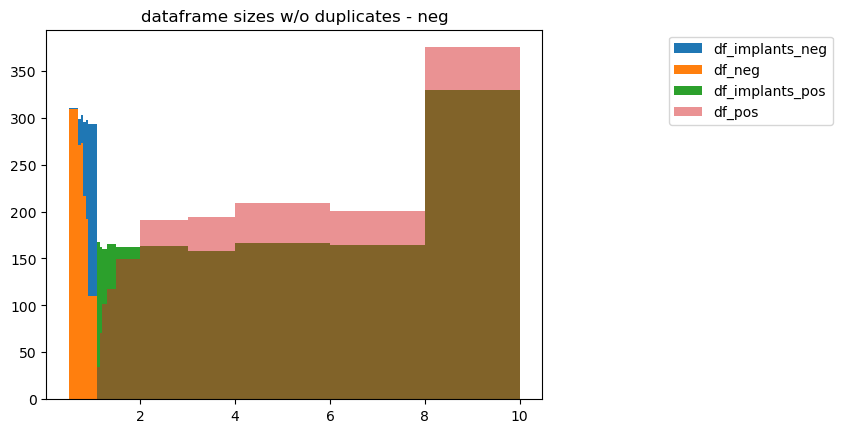

In [21]:

plt.hist(df_implants_neg["A_from_implant"],
                label="df_implants_neg", bins=binbounds)
plt.hist(df_neg.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])["A_from_implant"],
                label="df_neg", bins=binbounds)
plt.hist(df_implants_pos["A_from_implant"],
                label="df_implants_pos", bins=binbounds)
plt.hist(df_pos.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])["A_from_implant"],
                label="df_pos", bins=binbounds, alpha=.5)

plt.title("dataframe sizes w/o duplicates - neg")
plt.legend(bbox_to_anchor=(1.6, 1))

In [5]:
both = pd.concat([df_neg,df_pos], ignore_index=True)

In [6]:
noedges = rff.reduce_edges(both, 15)

Number of transient candidates reduced from 3018 to 3004.


In [7]:
def get_histtable(df):
    '''
    sort by the thing you want, it keeps the last (biggest)
    '''
    data = df.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")["A_from_implant"]
    print(len(data))
    return data

In [8]:
def make_bar(df, label, binbounds, ax, alpha=.5):
    data = get_histtable(df)
    hist, bin_edges = np.histogram(data,binbounds)
    return ax.bar(range(len(hist)),hist,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist)], alpha=alpha, label=label)


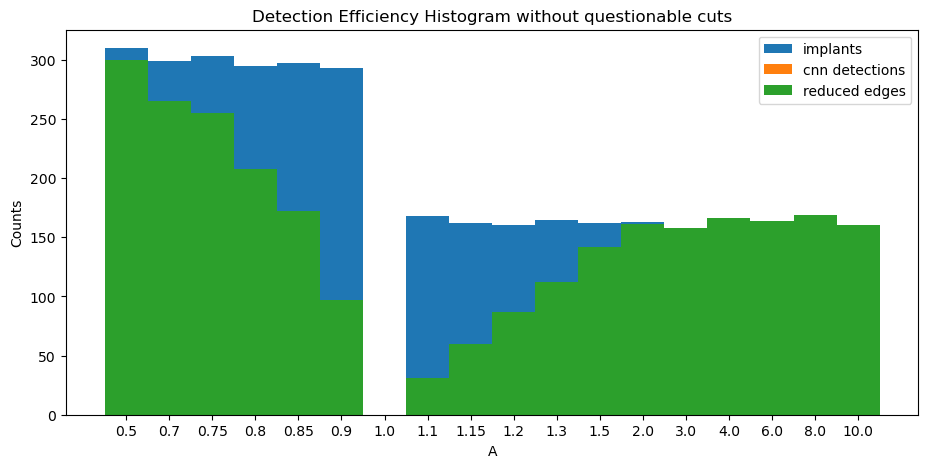

In [71]:
df_pos.iloc[0]

Unnamed: 0                                                19
filename            ztf_20221014162894_000802_zg_c02_x_0017.
detection_size                                           313
type                                                     pos
row_from_nn                                      2769.460064
col_from_nn                                      1908.389776
row_from_implant                                      1918.0
col_from_implant                                      2785.0
A_from_implant                                          10.0
sig_from_implant                                         9.0
Name: 0, dtype: object

In [70]:
both.iloc[0]['filename'][:35]


'ztf_20221020138241_000686_zi_c03_x_'

In [9]:
# def match_stars_eff(df):
#     closest_xs = np.zeros(len(df))
#     closest_ys= np.zeros(len(df))
#     Diffs = np.zeros(len(df))
#     brightness_ranking = np.zeros(len(df))
#     xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
#     quad = str(1)
#     i=0
#     for index, rrow in df.iterrows():

#         xy_file = xy_path+df.loc[index]['filename'][:35]+quad+".fits"
#         with fits.open(xy_file) as hdul_xy:
#             col = rrow["col_from_nn"]
#             target_x = col+10
#             # print(xy_file)
#             data = hdul_xy[1].data  
#             stored_x = data["X"][:25]  # Column "X"
#             stored_y = data["Y"][:25]
#             closest_idx = np.argmin(np.abs(stored_x - target_x))
            
#             closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
#             closest_xs[i]=closest_x
#             closest_ys[i]=closest_y
#             Diffs[i]=stored_x[closest_idx] - target_x
#             brightness_ranking[i]= closest_idx
#             # print(closest_idx)
#             # print(df.loc[index]['brightness_ranking'])
#             i+=1 #yes there is a better way to do this
#     df['closest_x'] = closest_xs
#     df['closest_y']= closest_ys
#     df['Diff'] = Diffs
#     df['brightness_ranking'] = brightness_ranking
#     return df


In [10]:
matched = match_stars_eff(noedges)

In [30]:
matched.to_csv(base_path+"matched")

In [11]:
matched['absdiff'] = np.abs(matched['Diff'])

In [111]:
matched.sort_values("absdiff") #smallest at top

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,closest_x,closest_y,Diff,brightness_ranking,absdiff
2602,3690,ztf_20221014162894_000802_zg_c01_x_0027.,1,pos,2764.000000,2302.000000,2312.0,2777.0,1.2,7.0,2312.0,134.0,0.000000,4.0,0.000000
1115,3413,ztf_20221020138241_000686_zi_c02_x_0026.,2,neg,1466.500000,2259.000000,2260.0,1483.0,0.7,3.0,2269.0,1069.0,0.000000,9.0,0.000000
2671,3896,ztf_20220820237546_000798_zr_c16_x_0001.,1,pos,1718.000000,601.000000,605.0,1734.0,8.0,6.0,611.0,320.0,0.000000,3.0,0.000000
1422,160,ztf_20220820237546_000798_zr_c16_x_0002.,3,pos,1831.000000,601.000000,605.0,1846.0,10.0,5.0,611.0,320.0,0.000000,3.0,0.000000
2046,2003,ztf_20221020138241_000686_zi_c03_x_0001.,218,pos,616.614679,2356.000000,2367.0,629.0,3.0,8.0,2366.0,541.0,0.000000,2.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,3785,ztf_20220820237546_000798_zr_c04_x_0004.,120,pos,2609.591667,995.316667,1005.0,2621.0,8.0,5.0,804.0,2355.0,-201.316667,2.0,201.316667
522,1581,ztf_20220820237546_000798_zr_c04_x_0004.,33,neg,2610.909091,995.333333,1005.0,2621.0,0.5,5.0,804.0,2355.0,-201.333333,2.0,201.333333
2265,2672,ztf_20220820237546_000798_zr_c04_x_0000.,59,pos,487.745763,995.474576,1005.0,500.0,2.0,9.0,804.0,2355.0,-201.474576,2.0,201.474576
1949,1725,ztf_20220820237546_000798_zr_c04_x_0002.,64,pos,2620.000000,995.578125,1005.0,2631.0,2.0,5.0,804.0,2355.0,-201.578125,2.0,201.578125


(-20.0, 20.0)

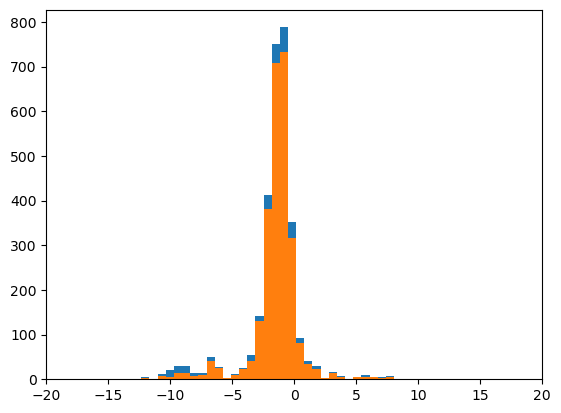

In [116]:

plt.hist(matched["Diff"], bins=500)
matched.sort_values("absdiff")
plt.hist(matched.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep='first')["Diff"], bins=500)

plt.xlim(-20,20)

In [123]:
matched

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,closest_x,closest_y,Diff,brightness_ranking,absdiff
0,15,ztf_20221020138241_000686_zi_c03_x_0015.,45,neg,2489.466667,1110.488889,1119.0,2500.0,0.80,4.0,1119.0,1094.0,-1.488889,7.0,1.488889
1,16,ztf_20221020138241_000686_zi_c03_x_0015.,59,neg,2287.033898,428.288136,439.0,2297.0,0.70,7.0,438.0,147.0,-0.288136,4.0,0.288136
2,17,ztf_20221020138241_000686_zi_c03_x_0015.,6,neg,1969.333333,1909.166667,1919.0,1980.0,0.90,5.0,1918.0,2162.0,-1.166667,3.0,1.166667
3,18,ztf_20221020138241_000686_zi_c03_x_0015.,42,neg,1806.547619,2355.071429,2367.0,1818.0,0.85,8.0,2366.0,541.0,0.928571,2.0,0.928571
4,19,ztf_20221020138241_000686_zi_c03_x_0015.,63,neg,1364.238095,958.158730,969.0,1375.0,0.70,9.0,968.0,825.0,-0.158730,0.0,0.158730
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3013,4961,ztf_20221014162894_000802_zg_c01_x_0005.,186,pos,1981.935484,1598.317204,1608.0,1994.0,6.00,7.0,1608.0,1444.0,-0.317204,6.0,0.317204
3014,4962,ztf_20221014162894_000802_zg_c01_x_0005.,213,pos,1326.230047,1322.638498,1332.0,1339.0,6.00,8.0,1331.0,1567.0,-1.638498,5.0,1.638498
3015,4963,ztf_20221014162894_000802_zg_c01_x_0005.,183,pos,1319.743169,1809.453552,1819.0,1332.0,3.00,8.0,1818.0,2123.0,-1.453552,3.0,1.453552
3016,4964,ztf_20221014162894_000802_zg_c01_x_0005.,56,pos,855.785714,2303.142857,2313.0,866.0,1.50,4.0,2312.0,134.0,-1.142857,4.0,1.142857


In [16]:
def add_snr_integrated(df, extension=None,  half_aperture=2, tracking=True, wid=10):
    """
    returns the dataframe with new columns for outputs of
    snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM 
    """
    column_names = ['snr_local', 'snr_global', 'noise_local', 'noise_global', 
                'local_average_outside', 'height', 'FWHM', 'signal_local']
    if half_aperture==3:
        column_names = ['snr_local_3', 'snr_global_3', 'noise_local_3', 'noise_global_3', 
                'local_average_outside_3', 'height_3', 'FWHM_3', 'signal_local_3']   
    elif half_aperture==4:
        column_names = ['snr_local_4', 'snr_global_4', 'noise_local_4', 'noise_global_4', 
                'local_average_outside_4', 'height_4', 'FWHM_4', 'signal_local_4']    
    for col in column_names:
        df[col] = np.zeros(len(df))
    
    for index in df.index:
        # print(index)
        tot, maxcols = rff.get_tot_npy(df, index)
        row = int(df.loc[index]["row_from_nn"]) + wid
        snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local = rff.get_snr_integrated(tot, row)
        df.loc[index, column_names] = [snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local]
    return df


In [140]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [11]:
matched["quadrant"]= np.full(len(matched), 1)

In [12]:
base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/"
snrs= pd.read_csv(base_path+"df_with_snrs") #note currently diff<10


(array([1.488e+03, 1.171e+03, 2.580e+02, 4.000e+01, 9.000e+00, 3.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 2.000e+00]),
 array([6.82927669e-03, 2.69245887e-01, 5.31662498e-01, 7.94079109e-01,
        1.05649572e+00, 1.31891233e+00, 1.58132894e+00, 1.84374555e+00,
        2.10616216e+00, 2.36857877e+00, 2.63099538e+00, 2.89341199e+00,
        3.15582861e+00, 3.41824522e+00, 3.68066183e+00, 3.94307844e+00,
        4.20549505e+00, 4.46791166e+00, 4.73032827e+00, 4.99274488e+00,
        5.25516149e+00, 5.51757810e+00, 5.77999471e+00, 6.04241132e+00,
        6.30482793e+00, 6.56724455e+00, 6.82966116e+00, 7.09207777e+00,
        7.35449438e+00, 7.61691099e+00, 7.87932760e+00]),
 <BarContainer object of 30 artists>)

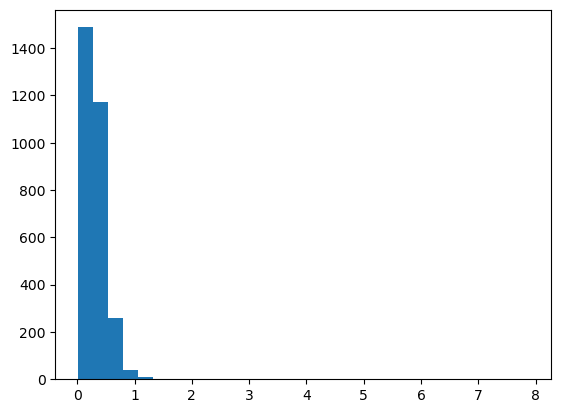

In [149]:
plt.hist(snrs["snr_local"], bins=30)

In [14]:
hist, bin_edges = np.histogram(data,binbounds)

NameError: name 'data' is not defined

2707
2693
2668
2653
2631
2533


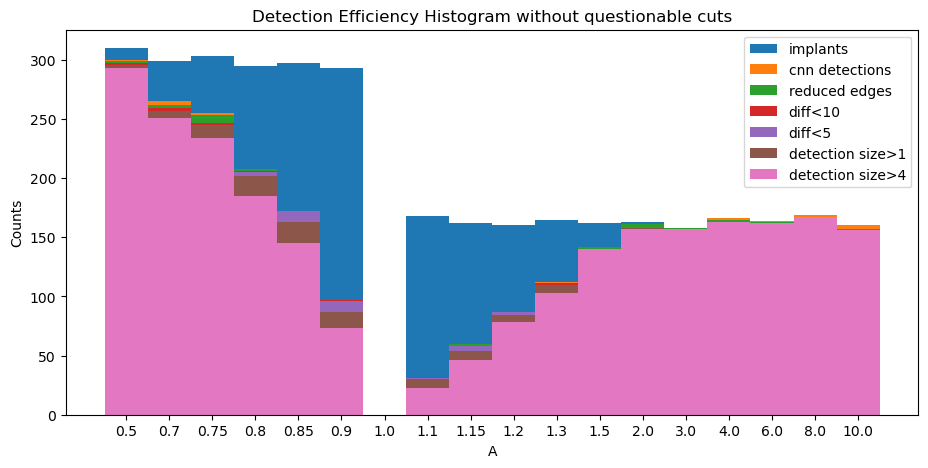

In [15]:
bins = binbounds
fig,ax = plt.subplots(figsize=(11,5))
alpha = 1

implants = np.concatenate([df_implants_neg["A_from_implant"],df_implants_pos["A_from_implant"]])
hist_implants, bin_edges = np.histogram(implants,bins) # make the histogram
ax.bar(range(len(hist_implants)),hist_implants,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist_implants)], alpha=alpha, label="implants")




make_bar(both, "cnn detections", binbounds, ax, alpha=alpha)
make_bar(noedges, "reduced edges", binbounds, ax, alpha=alpha)
make_bar(matched[matched["Diff"]<10], "diff<10", binbounds, ax, alpha=alpha)
make_bar(matched[matched["Diff"]<5], "diff<5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>.5].sort_values("snr_local"), "snr>0.5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>1].sort_values("snr_local"), "snr>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>3].sort_values("snr_local"), "snr>3", binbounds, ax, alpha=alpha)
make_bar(snrs[snrs["detection_size"]>1], "detection size>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>3], "detection size>3", binbounds, ax, alpha=alpha)
make_bar(snrs[snrs["detection_size"]>5], "detection size>4", binbounds, ax, alpha=alpha)


plt.title("Detection Efficiency Histogram without questionable cuts")
plt.ylabel("Counts")
plt.xlabel("A")
plt.legend()
plt.show()



In [56]:
dfsorted = snrs[snrs["Diff"]<5].sort_values('detection_size')

In [57]:
dfsorted

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,brightness_ranking,quadrant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
475,480,1450,ztf_20221014162894_000802_zg_c03_x_0011.,1,neg,196.000000,2712.000000,2727.0,206.0,0.75,...,3.0,1,0.170911,0.014184,30.120751,362.948316,1098.353128,49.227396,2.0,5.147981
1123,1139,3483,ztf_20221020138241_000686_zi_c05_x_0002.,1,neg,541.000000,586.000000,596.0,551.0,0.90,...,6.0,1,0.543360,0.509713,19.067595,20.326272,610.950476,49.300574,4.0,10.360572
2787,2833,4389,ztf_20221020138241_000686_zi_c03_x_0015.,1,pos,123.000000,2985.000000,2990.0,128.0,6.00,...,5.0,1,0.356785,0.110436,37.894371,122.424898,1590.934548,82.078879,5.0,13.520147
121,123,378,ztf_20221020138241_000686_zi_c01_x_0009.,1,neg,1311.000000,1326.000000,1333.0,1321.0,0.80,...,4.0,1,0.674940,0.167850,22.264642,89.527821,732.414114,52.443064,7.0,15.027287
2315,2355,2936,ztf_20221020138241_000686_zi_c07_x_0020.,1,pos,159.000000,1104.000000,1107.0,173.0,6.00,...,8.0,1,0.422305,0.099520,19.825808,84.129255,764.399196,34.316310,5.0,8.372546
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2003,2041,1998,ztf_20221020138241_000686_zi_c03_x_0001.,286,pos,1661.199301,700.178322,708.0,1677.0,10.00,...,8.0,1,0.217191,0.208282,28.303496,29.514127,1053.687872,60.384149,2.0,6.147270
2549,2592,3649,ztf_20221020138241_000686_zi_c01_x_0026.,287,pos,680.982578,755.261324,763.0,696.0,8.00,...,11.0,1,0.400442,0.020285,16.945621,334.523235,530.738186,37.200284,3.0,6.785732
1494,1518,438,ztf_20221020138241_000686_zi_c07_x_0000.,295,pos,48.644068,1099.061017,1106.0,64.0,10.00,...,8.0,1,0.394218,0.337212,22.702724,26.540670,763.017115,52.074855,3.0,8.949833
2184,2223,2531,ztf_20221014162894_000802_zg_c01_x_0025.,295,pos,871.216949,1124.105085,1132.0,886.0,10.00,...,9.0,1,0.328618,0.027986,17.007776,199.708859,559.219967,30.084110,3.0,5.589055


In [76]:
dfsorted = dfsorted.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep='last')

(array([370., 336., 331., 305., 261., 170., 127., 141.,  97.,  98.,  80.,
         87.,  49.,  64.,  45.,  57.,  18.,  10.,   6.,   1.]),
 array([  1. ,  16.6,  32.2,  47.8,  63.4,  79. ,  94.6, 110.2, 125.8,
        141.4, 157. , 172.6, 188.2, 203.8, 219.4, 235. , 250.6, 266.2,
        281.8, 297.4, 313. ]),
 <BarContainer object of 20 artists>)

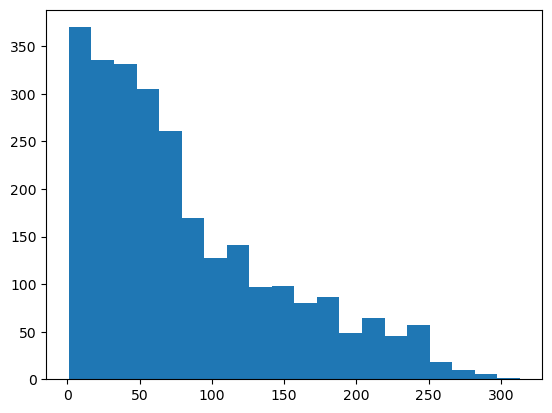

In [78]:
plt.hist(dfsorted['detection_size'], bins=20)
# plt.xlim(0,6)

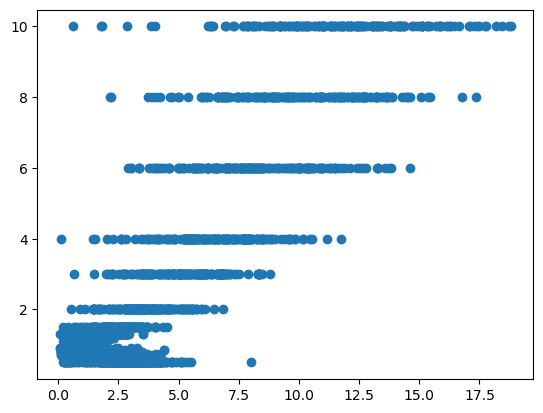

In [299]:
plt.scatter(snrs["snr_local"], snrs["A_from_implant"])

In [155]:
snrs.sort_values("snr_local")

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,brightness_ranking,quadrant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
851,862,2614,ztf_20221020138241_000686_zi_c06_x_0009.,54,neg,238.111111,456.500000,467.0,248.0,0.50,...,10.0,1,0.006829,0.024676,2438.395700,674.836474,1979.692757,1819.662712,2.0,16.652479
2726,2771,4210,ztf_20220820237546_000798_zr_c09_x_0000.,1,pos,1517.000000,2181.000000,2184.0,1523.0,6.00,...,6.0,1,0.009316,0.033418,817.317089,227.848057,657.666559,514.957464,2.0,7.614298
618,623,1891,ztf_20221020138241_000686_zi_c01_x_0001.,25,neg,2695.080000,1314.400000,1325.0,2705.0,0.70,...,4.0,1,0.012365,0.005570,203.314175,451.306732,776.532000,36.347796,2.0,2.513938
597,602,1819,ztf_20221017148750_000831_zi_c03_x_0028.,68,neg,406.882353,1098.764706,1109.0,417.0,0.50,...,4.0,1,0.014525,0.052866,375.055468,103.047095,562.841414,411.393815,2.0,5.447691
2909,2955,4767,ztf_20221020138241_000686_zi_c06_x_0010.,129,pos,1072.023256,1296.573643,1306.0,1083.0,8.00,...,4.0,1,0.015782,0.025470,160.472768,99.432454,2224.014124,27.977087,2.0,2.532504
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,66,210,ztf_20221020138241_000686_zi_c01_x_0000.,42,neg,2621.738095,1684.238095,1693.0,2633.0,0.75,...,1.0,1,1.330151,1.403301,49.672322,47.083055,1191.597593,122.085508,46.0,66.071685
348,352,1057,ztf_20221020138241_000686_zi_c01_x_0005.,43,neg,1342.302326,1191.186047,1200.0,1352.0,0.75,...,10.0,1,1.330213,4.657631,330.543440,94.402781,577.449142,131.159439,1602.0,439.693293
339,343,1031,ztf_20220820237546_000798_zr_c07_x_0003.,26,neg,1056.653846,1799.769231,1809.0,1066.0,0.70,...,6.0,1,1.873609,4.780785,47.711499,18.698334,321.265288,610.058625,17.0,89.392713
916,929,2823,ztf_20220820237546_000798_zr_c15_x_0000.,50,neg,1083.820000,1056.440000,1066.0,1094.0,0.50,...,8.0,1,7.861709,7.624901,12.814197,13.212170,320.041755,1619.373406,9.0,100.741495


In [168]:
snrs[(snrs['filename']=='ztf_20220820237546_000798_zr_c09_x_0000.')* (snrs['col_from_implant']==1523.0) 	]

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,brightness_ranking,quadrant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
57,58,191,ztf_20220820237546_000798_zr_c09_x_0000.,40,neg,1512.500000,2174.850000,2184.0,1523.0,0.5,...,6.0,1,0.823247,2.923655,835.301858,235.205448,692.557072,290.373295,1527.0,687.659515
2726,2771,4210,ztf_20220820237546_000798_zr_c09_x_0000.,1,pos,1517.000000,2181.000000,2184.0,1523.0,6.0,...,6.0,1,0.009316,0.033418,817.317089,227.848057,657.666559,514.957464,2.0,7.614298
2727,2772,4211,ztf_20220820237546_000798_zr_c09_x_0000.,112,pos,1512.205357,2175.303571,2184.0,1523.0,6.0,...,6.0,1,0.823247,2.923655,835.301858,235.205448,692.557072,290.373295,1527.0,687.659515


In [41]:
def inspect_stamp_and_map(df, index, posneg, size=10, column=None, nn_or_imp="nn", thr=True, star=False):
    wid = 10
    if column!=None:
        index = df[df[column]==index].index[0]
    if posneg=="pos":
        extension = "_1_implanted_pos.npy"
        fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/images/'
        ppath = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/predsarrays/"

    elif posneg=="neg":
        extension = "_1_implanted_neg.npy"
        fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/images/'
        ppath = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/predsarrays/"

    if nn_or_imp=="nn":
        fig, ax = plt.subplots(1, 2, figsize=(7,2))
    else:
        fig, ax = plt.subplots(1, 3, figsize=(10,2))
    fname = df.loc[index]["filename"] + extension
    # print(df.iloc[index]["filename"])
    if nn_or_imp == "nn":
        row = int(df.loc[index]["row_from_nn"])+wid
        col = int(df.loc[index]["col_from_nn"])+wid
    elif nn_or_imp == "imp":
        row = int(df.loc[index]["col_from_implant"])
        col = int(df.loc[index]["row_from_implant"])
    path = fpath + fname
    array = np.load(path)
    imj = ax[0].imshow(
                
                    array[
                        row - size : row + size ,
                        col  - size : col  + size,
                    ]
                
                )
    nrow, ncol = array.shape
    if posneg =="pos":
        pfile = df.loc[index]["filename"]+"_extraction_predsarray_pos_predsarray.npy"
        predsarray = np.load(ppath+pfile)
        pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    elif posneg=="neg":
        pfile = df.loc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
        predsarray = np.load(ppath+pfile)
        pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    if thr:
        ax[1].imshow(
        
                    pimg[
                        col - size  - wid : col + size - wid,
                        row  - size - wid: row  + size - wid,
                    ].T>.9999
                )
    else:
        ax[1].imshow(
        
                    pimg[
                        col - size  - wid: col + size - wid,
                        row  - size - wid: row  + size - wid,
                    ].T
                )
        ax[2].imshow(
        
                    pimg[
                        col - size  - wid: col + size - wid,
                        row  - size - wid : row  + size - wid,
                    ].T>.9999
                )
        ax[2].set_title("CNN Thresholded")
    if star==True:
                    starpos = df.loc[index]['closest_x']
                    ax[0].scatter(starpos- (col - size  + wid), 10)
#     pfile_pos = df.iloc[index]["filename"]+"_extraction_predsarray_pos_predsarray.npy"
#     predsarray_pos = np.load(ppath+pfile_pos)
#     pimg_pos = predsarray_pos[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
#     pfile_neg = df.iloc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
#     predsarray_neg = np.load(ppath+pfile_neg)
#     pimg_neg = predsarray_neg[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
#     ax[1].imshow(
        
#                     pimg_neg[
#                         col - size : col + size,
#                         row  - size : row  + size,
#                     ].T>.9999
#                 )
#     ax[2].imshow(pimg_pos[
#                         col - size : col + size,
#                         row  - size : row  + size,
#                     ].T>.9999
#                 )            
    ax[0].annotate(
    "Injection",
    xy=(  df["row_from_implant"].loc[index]-col+size,df["col_from_implant"].loc[index]-row+size),
    xytext=(size+3*size/4, size/2),  
    arrowprops=dict(
        facecolor="red",
        edgecolor="red",
        # shrink=1.0,
        # headlength=5,
        # headwidth=3,
    ),
    color="white",
    fontsize=10,
    ha="center",
    # va="top",
    rotation=0,
    zorder=10,
)
    ax[0].set_title("Injected image, Index "+str(index)+ ", A = "+str(df["A_from_implant"].loc[index])+", sig = "+str(df["sig_from_implant"].loc[index]))
    ax[1].set_title("CNN "+str(posneg)+" prediction")
    # ax[2].set_title("CNN pos prediction")
    # print(df["row_from_implant"].iloc[index], col, df["col_from_implant"].iloc[index], row)
    fig.colorbar(imj, orientation='horizontal')
    plt.show()

In [208]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [176]:
snrs.loc[2727]["snr_local"]

0.8232467205852537

In [319]:
tot, maxcols = rff.get_tot_npy(snrs, 2727, posneg="pos")

(1472.205357142857, 1572.205357142857)

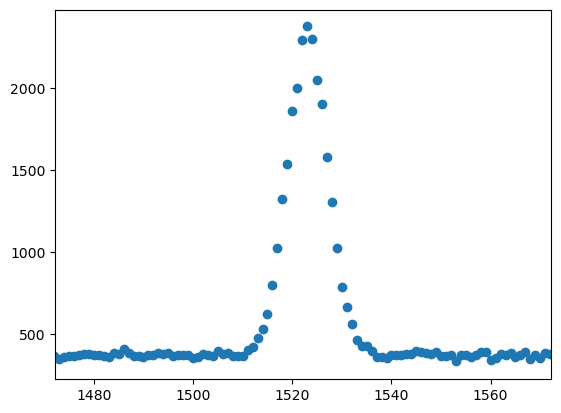

In [212]:

plt.scatter(range(len(tot)),tot)
plt.xlim(snrs.loc[2727]["row_from_nn"]+10-50,snrs.loc[2727]["row_from_nn"]+10+50)

In [207]:
snrs.loc[2727]

Unnamed: 0.1                                                 2772
Unnamed: 0                                                   4211
filename                 ztf_20220820237546_000798_zr_c09_x_0000.
detection_size                                                112
type                                                          pos
row_from_nn                                           1512.205357
col_from_nn                                           2175.303571
row_from_implant                                           2184.0
col_from_implant                                           1523.0
A_from_implant                                                6.0
sig_from_implant                                              4.0
closest_x                                                  2184.0
closest_y                                                   925.0
Diff                                                    -1.303571
brightness_ranking                                            6.0
quadrant  

In [186]:
int(snrs.loc[2727]["row_from_nn"]+10)

1522

(array([1011.,  643.,  433.,  273.,  195.,  167.,  113.,  102.,   28.,
           7.]),
 array([  1. ,  32.2,  63.4,  94.6, 125.8, 157. , 188.2, 219.4, 250.6,
        281.8, 313. ]),
 <BarContainer object of 10 artists>)

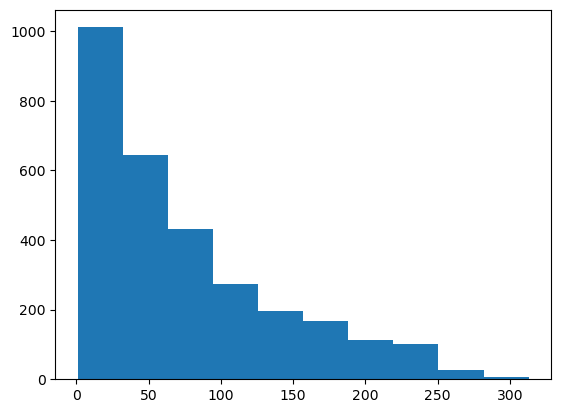

In [216]:
plt.hist(snrs['detection_size'])

In [213]:
rff.get_snr_integrated(tot, int(snrs.loc[2727]["row_from_nn"]+10), new_width_restriction=True, detection_size=None)

newwid  10
tallest_index,  11
absolute  1523
height  2004.798948059082
local_average_outside  372.498659362793
indices for size of integral:  5 6


(7.599791030217404,
 7.102828700474367,
 16.873559516862304,
 18.054148800677872,
 372.498659362793,
 2004.798948059082,
 11,
 128.23552626408966)

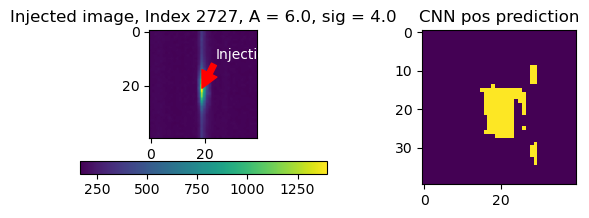

In [205]:
inspect_stamp_and_map(snrs, 2727, "pos", size=20, column=None, nn_or_imp="nn", thr=True)

In [12]:
snrs= pd.read_csv(base_path+"df_with_snrs_corrected_again")

In [245]:
snrs = snrs.sort_values(["snr_local"])

In [247]:
snrs_drop = snrs.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")

In [248]:
little = snrs_drop[snrs_drop['snr_local']<.5]

In [249]:
littleandbright = little[little["A_from_implant"]>5]

In [250]:
littleandbright

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,brightness_ranking,quadrant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
1671,1727,1047,ztf_20221017148750_000831_zi_c01_x_0014.,244,pos,1776.401639,1053.946721,1065.0,1790.0,8.0,...,0.0,1,0.122592,0.443059,9332.820967,2582.333338,14551.672979,76295.248896,22.0,1144.127072
2733,2809,4315,ztf_20221017148750_000831_zi_c01_x_0012.,193,pos,2495.813472,1054.290155,1066.0,2508.0,10.0,...,0.0,1,0.153033,0.559386,7911.618236,2164.400749,13633.202798,101870.812827,19.0,1210.735945
2677,2751,4140,ztf_20221020138241_000686_zi_c07_x_0025.,256,pos,1031.562500,2917.699219,2928.0,1045.0,10.0,...,1.0,1,0.167775,0.607675,4947.808101,1366.058686,5967.534707,38995.098105,23.0,830.119475
2813,2889,4572,ztf_20221014162894_000802_zg_c02_x_0021.,246,pos,1206.483740,2307.264228,2319.0,1220.0,10.0,...,0.0,1,0.168021,0.609947,4844.457215,1334.491715,5737.216488,37179.260074,23.0,813.968850
2029,2090,2145,ztf_20221020138241_000686_zi_c03_x_0008.,246,pos,59.902439,2982.910569,2991.0,75.0,10.0,...,5.0,1,0.188788,0.962313,2241.059601,439.655658,2338.897181,14221.518834,17.0,423.086271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1643,1698,983,ztf_20221014162894_000802_zg_c01_x_0010.,259,pos,2371.737452,3029.637066,3039.0,2385.0,10.0,...,17.0,1,0.484678,1.743919,578.866080,160.881251,700.167882,4590.911219,22.0,280.563842
2252,2319,2828,ztf_20221014162894_000802_zg_c03_x_0018.,200,pos,1336.765000,2717.025000,2727.0,1349.0,10.0,...,3.0,1,0.488554,1.770348,769.271214,212.291849,1308.533978,9947.096882,19.0,375.830472
1961,2022,1939,ztf_20221014162894_000802_zg_c03_x_0000.,219,pos,2603.013699,1918.232877,1927.0,2616.0,10.0,...,7.0,1,0.491367,1.780681,671.587385,185.319978,975.719769,7374.079059,19.0,329.995692
1960,2021,1926,ztf_20221020138241_000686_zi_c05_x_0010.,250,pos,176.528000,86.608000,95.0,190.0,10.0,...,10.0,1,0.491475,1.775250,564.956669,156.407258,688.993715,4624.063414,22.0,277.662052


(array([ 3.,  7., 11., 10., 33., 16.,  7.,  7.,  3.,  1.]),
 array([183., 196., 209., 222., 235., 248., 261., 274., 287., 300., 313.]),
 <BarContainer object of 10 artists>)

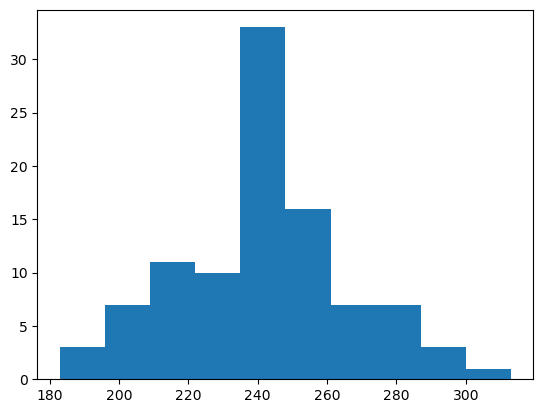

In [251]:
plt.hist(littleandbright["detection_size"])

In [241]:
littleandbright.index

Int64Index([1334, 1338, 1341, 1367, 1375, 1397, 1402, 1409, 1416, 1422,
            ...
            2813, 2843, 2848, 2850, 2868, 2874, 2875, 2900, 2906, 2913],
           dtype='int64', length=138)

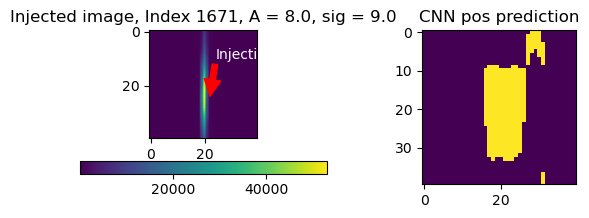

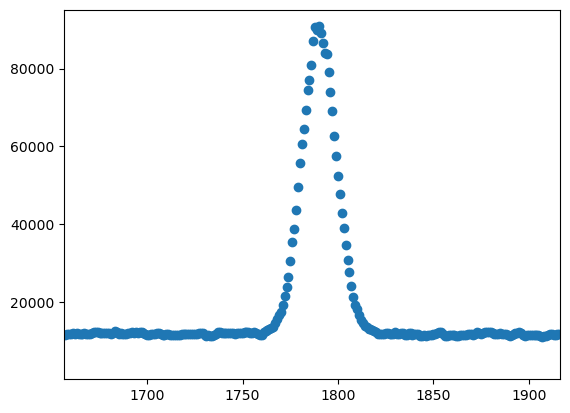

In [280]:
for index in littleandbright.index[:1]:
    
    inspect_stamp_and_map(littleandbright, index, littleandbright.loc[index]["type"], size=20, column=None, nn_or_imp="nn", thr=True)
    tot, maxcols = rff.get_tot_npy(littleandbright, index, posneg = littleandbright.loc[index]["type"])
    plt.scatter(range(len(tot)),tot)
    plt.xlim(littleandbright.loc[index]["row_from_nn"]+10-130,littleandbright.loc[index]["row_from_nn"]+10+130)
    plt.show()

In [266]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [323]:
index = littleandbright.index[0]
tot, maxcols = rff.get_tot_npy(littleandbright, index, posneg = littleandbright.loc[index]["type"])
row = int(littleandbright.loc[index]["row_from_nn"]+10)
rff.get_snr_integrated(tot, row)

(0.12259177328008675,
 0.44305940495732116,
 9332.820966909854,
 2582.33333778179,
 14551.672978515626,
 76295.24889648438,
 22,
 1144.1270720390528)

In [324]:
new_width_restriction=True
detection_size=200



if True==True:
    if new_width_restriction and detection_size!=None: #takes effect if it's true and if detection size is big and was put in
        if np.sqrt(detection_size)/2>10:
            newwid = int(np.sqrt(detection_size)/2)
        else:
            newwid = 10
    else:
        newwid = 10
    print("newwid ", newwid)
    if new_width_restriction:
        tallest_index = np.argmax(tot[row - newwid : row + newwid])
        print("tallest_index, ", tallest_index)
        tallest_index_absolute = tallest_index+(row - newwid)
        print("absolute ",tallest_index_absolute)
        local_outside = np.concatenate((tot[ tallest_index_absolute - 100 - (detection_size) : tallest_index_absolute - (detection_size)], tot[tallest_index_absolute + (detection_size) : tallest_index_absolute + 100+ (detection_size)]))
        local_average_outside = np.average(local_outside)
        tot_subtracted = np.abs(tot - local_average_outside)
        height = tot_subtracted[tallest_index_absolute]
        print("height ",height)
        print("local_average_outside ", local_average_outside)
        half_max = height/2
        row = tallest_index_absolute #so the rest can stay the same
    else: #old version
        local_outside = np.concatenate((tot[ row - 100 - newwid : row - newwid], tot[row + newwid : row + 100+ newwid]))
        local_average_outside = np.average(local_outside)
        
        tot_subtracted = np.abs(tot - local_average_outside)
        height = np.max(tot_subtracted[row - newwid : row + newwid])
        half_max = height/2

    
    
    arr_left = tot_subtracted[ : row ][::-1]
    arr_right = tot_subtracted[row : ]
    
    left_index = next((i for i,v in enumerate(arr_left) if v<half_max), len(arr_left)-1) + 1
    right_index = next((i for i,v in enumerate(arr_right) if v<half_max), len(arr_right)-1) + 1
    #using the last one if none found
    # print("indices for size of integral: ", left_index, right_index)
    window_minus_average = tot_subtracted[row - left_index : row + right_index]
    FWHM = len(window_minus_average)
    print("FWHM, ",FWHM)
    
    integrated_window = np.sum(window_minus_average)
    print("integrated_window ", integrated_window)
    signal_local = np.sqrt(np.abs(integrated_window))
    noise_local = np.std(local_outside)
    noise_global = np.std(np.concatenate((tot[ 100 : row - newwid], tot[row + newwid : -100])))
    snr_local = signal_local/noise_local
    snr_global = signal_local/noise_global

newwid  10
tallest_index,  14
absolute  1790
height  79156.74584472657
local_average_outside  11690.176030273438
FWHM,  23
integrated_window  1407996.0567724602


In [325]:
signal_local, noise_local

(1186.590096356977, 265.03249596427816)

In [286]:
signal_local, noise_local

(1183.5598537493686, 897.0376950644562)

In [293]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [326]:
rff.get_snr_integrated(tot, row, new_width_restriction=True, detection_size=200)

tallest_index,  10
absolute  1790
height  79156.74584472657
local_average_outside  11690.176030273438


(4.4771494606341,
 0.6040832518027213,
 265.03249596427816,
 1964.2823945473135,
 11690.176030273438,
 79156.74584472657,
 23,
 1186.590096356977)

In [296]:
snr_local

4.4771494606341

In [275]:
littleandbright[:1]

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,brightness_ranking,quadrant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
1671,1727,1047,ztf_20221017148750_000831_zi_c01_x_0014.,244,pos,1776.401639,1053.946721,1065.0,1790.0,8.0,...,0.0,1,0.122592,0.443059,9332.820967,2582.333338,14551.672979,76295.248896,22.0,1144.127072


In [279]:
signal_local/noise_local

0.16374742736488554

In [25]:
from scipy.signal import savgol_filter

In [24]:
#checking out fed's code

def highpass_filter(data, window=101, order=3):
    """Apply Savitzky-Golay filter for smoothing or derivative"""

    return data - savgol_filter(data, window, order, axis=0) #was 1
     



In [309]:
savgol_filter?

Signature:
savgol_filter(
    x,
    window_length,
    polyorder,
    deriv=0,
    delta=1.0,
    axis=-1,
    mode='interp',
    cval=0.0,
)
Docstring:
Apply a Savitzky-Golay filter to an array.

This is a 1-D filter. If `x`  has dimension greater than 1, `axis`
determines the axis along which the filter is applied.

Parameters
----------
x : array_like
    The data to be filtered. If `x` is not a single or double precision
    floating point array, it will be converted to type ``numpy.float64``
    before filtering.
window_length : int
    The length of the filter window (i.e., the number of coefficients).
    If `mode` is 'interp', `window_length` must be less than or equal
    to the size of `x`.
polyorder : int
    The order of the polynomial used to fit the samples.
    `polyorder` must be less than `window_length`.
deriv : int, optional
    The order of the derivative to compute. This must be a
    nonnegative integer. The default is 0, which means to filter
    the data withou

In [306]:
tot
X = tot

In [330]:
hpflcs = highpass_filter(X, window=101, order=3)

In [312]:
hpflcs

array([-6147.22212257,   558.89236293,   587.01164207, ...,
        -526.85891012,  -424.80578622,  -373.24032945])

In [314]:
hpflcs

array([ 6185.2550915 , 12891.369577  , 12919.48885614, ...,
       11805.61830395, 11907.67142785, 11959.23688462])

In [315]:
tot

array([ 4428.25976562, 11222.11621094, 11334.40820312, ...,
       11023.19042969, 11122.13867188, 11170.88574219])

In [327]:
rff.get_snr_integrated(tot, row, new_width_restriction=True, detection_size=200)

tallest_index,  10
absolute  1790
height  79156.74584472657
local_average_outside  11690.176030273438


(4.4771494606341,
 0.6040832518027213,
 265.03249596427816,
 1964.2823945473135,
 11690.176030273438,
 79156.74584472657,
 23,
 1186.590096356977)

In [331]:
rff.get_snr_integrated(hpflcs, row, new_width_restriction=True, detection_size=200)

tallest_index,  8
absolute  1788
height  42255.05324616819
local_average_outside  4.766472468651436


(2.990267125473639,
 0.3417394139014257,
 244.83294819222647,
 2142.3221508280085,
 4.766472468651436,
 42255.05324616819,
 17,
 732.1159162120053)

In [313]:
# Xmean = X.mean(axis=0, keepdims=True)
# hpflcs = highpass_filter(X, window=101, order=3)
# hpflcs = hpflcs + Xmean

In [329]:
highpass_filter?

Signature: highpass_filter(data, window=101, order=3)
Docstring: Apply Savitzky-Golay filter for smoothing or derivative
File:      /tmp/ipykernel_20756/1615560405.py
Type:      function

In [339]:
def add_hpf_snr(df,  half_aperture=2):
    """
    returns the dataframe with new columns for outputs of
    snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM 
    """
    wid=10
    column_names = ['snr_local_hpf', 'snr_global_hpf', 'noise_local_hpf', 'noise_global_hpf', 
                'local_average_outside_hpf', 'height_hpf', 'FWHM_hpf', 'signal_local_hpf']

    for col in column_names:
        df[col] = np.zeros(len(df))
    
    for index in df.index:
        # print(index)
        tot_original, maxcols = rff.get_tot_npy(df, index, df.loc[index]["type"])
        tot = highpass_filter(tot_original, window=101, order=3)
        row = int(df.loc[index]["row_from_nn"]) + wid
        snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local = rff.get_snr_integrated(tot, row)
        df.loc[index, column_names] = [snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local]
    return df


In [342]:
snrs

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,FWHM,signal_local,snr_local_hpf,snr_global_hpf,noise_local_hpf,noise_global_hpf,local_average_outside_hpf,height_hpf,FWHM_hpf,signal_local_hpf
0,0,15,ztf_20221020138241_000686_zi_c03_x_0015.,45,neg,2489.466667,1110.488889,1119.0,2500.0,0.80,...,36.0,54.883216,1.221840,1.351959,32.852271,29.690420,7.278044,223.941852,11.0,40.140232
1,1,16,ztf_20221020138241_000686_zi_c03_x_0015.,59,neg,2287.033898,428.288136,439.0,2297.0,0.70,...,28.0,95.034585,0.945756,1.520429,66.864177,41.591687,21.036395,376.102966,14.0,63.237211
2,2,17,ztf_20221020138241_000686_zi_c03_x_0015.,6,neg,1969.333333,1909.166667,1919.0,1980.0,0.90,...,11.0,15.101714,0.891821,0.988750,37.127922,33.488198,5.770720,139.665323,11.0,33.111471
3,3,18,ztf_20221020138241_000686_zi_c03_x_0015.,42,neg,1806.547619,2355.071429,2367.0,1818.0,0.85,...,83.0,208.617627,0.184129,0.234302,136.250089,107.073778,22.221010,698.705469,2.0,25.087555
4,4,19,ztf_20221020138241_000686_zi_c03_x_0015.,63,neg,1364.238095,958.158730,969.0,1375.0,0.70,...,34.0,129.534688,0.797753,1.350005,102.249097,60.421603,32.355440,509.000811,18.0,81.569483
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2937,3013,4961,ztf_20221014162894_000802_zg_c01_x_0005.,186,pos,1981.935484,1598.317204,1608.0,1994.0,6.00,...,17.0,190.584228,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
2938,3014,4962,ztf_20221014162894_000802_zg_c01_x_0005.,213,pos,1326.230047,1322.638498,1332.0,1339.0,6.00,...,20.0,231.477115,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
2939,3015,4963,ztf_20221014162894_000802_zg_c01_x_0005.,183,pos,1319.743169,1809.453552,1819.0,1332.0,3.00,...,20.0,160.155956,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
2940,3016,4964,ztf_20221014162894_000802_zg_c01_x_0005.,56,pos,855.785714,2303.142857,2313.0,866.0,1.50,...,11.0,54.380721,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000


In [340]:
snrs2 = add_hpf_snr(snrs,  half_aperture=2)`a

KeyboardInterrupt: 

In [4]:
with_hpf = pd.read_csv(base_path+"df_with_hpf_snrs")

Text(0.5, 0, 'right hand side means better snr with hpf')

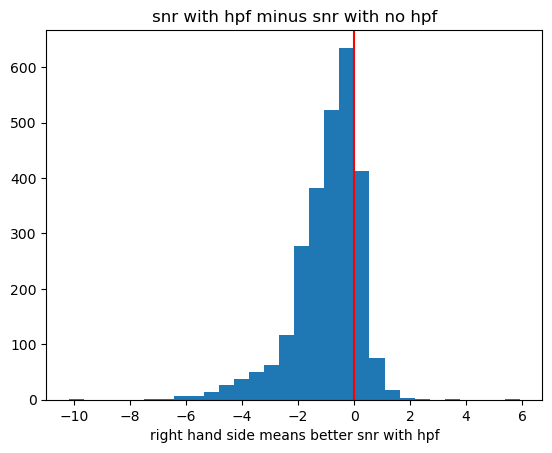

In [15]:
snrdiff = with_hpf_nodup['snr_local_hpf']-with_hpf_nodup['snr_local']
plt.hist(snrdiff, bins=30)
plt.axvline(x=0, c="red")
plt.title("snr with hpf minus snr with no hpf")
plt.xlabel("right hand side means better snr with hpf")

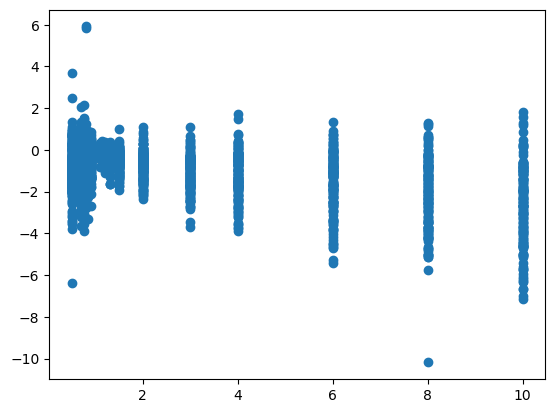

In [39]:
snrdiff = with_hpf_nodup['snr_local_hpf']-with_hpf_nodup['snr_local']
plt.scatter(with_hpf_nodup["A_from_implant"], snrdiff)

In [7]:
with_hpf.sort_values("snr_local") #smallest at top
with_hpf_nodup = with_hpf.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")


In [16]:
with_hpf_nodup["snr_diff"] = with_hpf_nodup['snr_local_hpf']-with_hpf_nodup['snr_local']

/tmp/ipykernel_62179/3088437864.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  with_hpf_nodup["snr_diff"] = with_hpf_nodup['snr_local_hpf']-with_hpf_nodup['snr_local']


In [18]:
with_hpf_nodup.sort_values("snr_diff")

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,...,signal_local,snr_local_hpf,snr_global_hpf,noise_local_hpf,noise_global_hpf,local_average_outside_hpf,height_hpf,FWHM_hpf,signal_local_hpf,snr_diff
1437,1437,1481,344,ztf_20221020138241_000686_zi_c07_x_0017.,230,pos,2965.078261,1661.508696,1671.0,2978.0,...,353.634061,2.593066,8.436382,87.901751,27.018105,8.277621,4462.637384,15.0,227.935048,-10.190550
1643,1643,1698,983,ztf_20221014162894_000802_zg_c01_x_0010.,259,pos,2371.737452,3029.637066,3039.0,2385.0,...,291.119994,11.662053,12.691339,15.075851,13.853177,1.077990,2526.134781,16.0,175.815377,-7.145631
1891,1891,1951,1727,ztf_20220820237546_000798_zr_c04_x_0002.,237,pos,1387.362869,584.413502,594.0,1401.0,...,360.375184,11.745130,11.073998,18.607859,19.735576,0.567960,3873.021595,16.0,218.551728,-6.989314
1539,1539,1591,660,ztf_20220820237546_000798_zr_c14_x_0004.,272,pos,2777.338235,344.580882,353.0,2791.0,...,247.632374,11.118458,11.029100,13.066527,13.172392,-0.039888,2035.111023,14.0,145.279628,-6.654757
2103,2103,2168,2376,ztf_20221017148750_000831_zi_c04_x_0007.,267,pos,1269.262172,1204.337079,1214.0,1283.0,...,249.662043,10.837355,10.501255,13.983378,14.430925,-0.108599,1899.576791,16.0,151.542829,-6.648856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1289,1289,1328,4098,ztf_20220820237546_000798_zr_c14_x_0004.,1,neg,2410.000000,366.000000,376.0,2420.0,...,59.737163,5.359746,5.346026,18.107004,18.153473,0.002231,0.489877,501.0,97.048935,2.134331
566,566,579,1748,ztf_20220820237546_000798_zr_c14_x_0003.,56,neg,292.375000,1961.571429,1972.0,303.0,...,77.529850,6.358606,5.779325,18.613143,20.478803,0.839584,0.371102,542.0,118.353649,2.467911
1048,1048,1080,3281,ztf_20221020138241_000686_zi_c07_x_0000.,57,neg,1661.315789,2475.771930,2486.0,1672.0,...,93.447234,6.760415,6.853666,26.691695,26.328525,-0.281753,0.092263,1159.0,180.446929,3.686459
608,608,628,1896,ztf_20221020138241_000686_zi_c01_x_0001.,33,neg,1216.757576,753.696970,763.0,1227.0,...,44.494631,8.460853,7.262157,15.129260,17.626506,-0.064272,0.129309,1084.0,128.006448,5.828841


In [ ]:
#maybe show some light curve and image examples where there
#are high differences

In [21]:
tot, maxcols = rff.get_tot_npy(with_hpf_nodup, 1437, with_hpf_nodup.loc[1437]["type"])

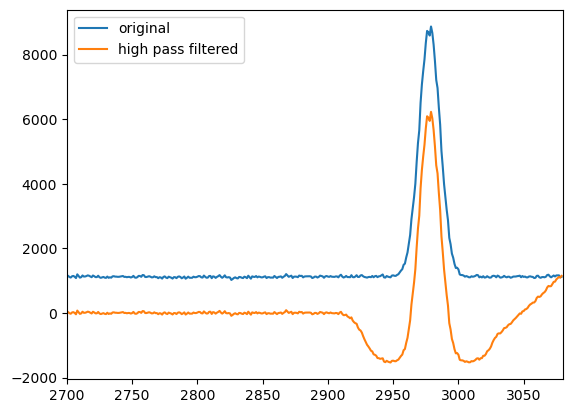

In [37]:
plt.plot(tot, label="original")
plt.plot(highpass_filter(tot, window=101, order=1), label="high pass filtered")
plt.xlim(2700, 3080)
plt.legend()

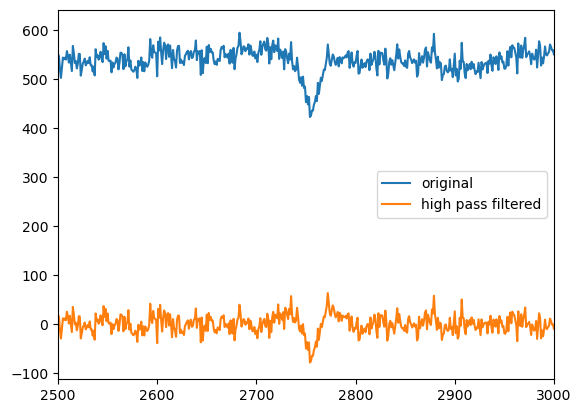

In [32]:
tot2, maxcols = rff.get_tot_npy(with_hpf_nodup, 1248, with_hpf_nodup.loc[1248]["type"])
plt.plot(tot2, label="original")
plt.plot(highpass_filter(tot2, window=101, order=3), label="high pass filtered")
plt.xlim(2500, 3000)
plt.legend()

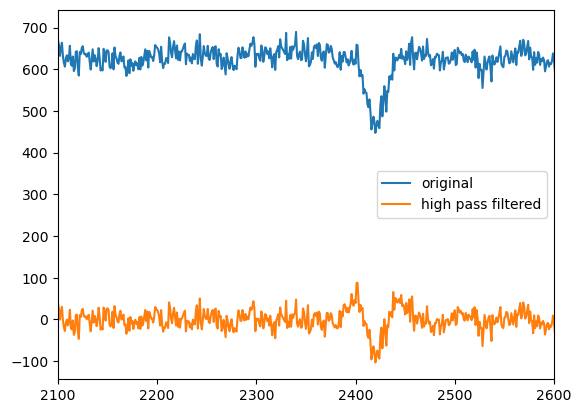

In [34]:


tot2, maxcols = rff.get_tot_npy(with_hpf_nodup, 1289, with_hpf_nodup.loc[1289]["type"])
plt.plot(tot2, label="original")
plt.plot(highpass_filter(tot2, window=101, order=3), label="high pass filtered")
plt.xlim(2100, 2600)
plt.legend()

In [13]:
snrs

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,brightness_ranking,quadrant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
0,0,15,ztf_20221020138241_000686_zi_c03_x_0015.,45,neg,2489.466667,1110.488889,1119.0,2500.0,0.80,...,7.0,1,1.555536,1.700951,35.282512,32.266191,1257.002297,8.147728,36.0,54.883216
1,1,16,ztf_20221020138241_000686_zi_c03_x_0015.,59,neg,2287.033898,428.288136,439.0,2297.0,0.70,...,4.0,1,2.168329,2.254720,43.828481,42.149178,1793.318469,217.928699,28.0,95.034585
2,2,17,ztf_20221020138241_000686_zi_c03_x_0015.,6,neg,1969.333333,1909.166667,1919.0,1980.0,0.90,...,3.0,1,0.437464,0.408782,34.521041,36.943204,1512.000365,12.041017,11.0,15.101714
3,3,18,ztf_20221020138241_000686_zi_c03_x_0015.,42,neg,1806.547619,2355.071429,2367.0,1818.0,0.85,...,2.0,1,2.780755,1.101981,75.021943,189.311490,2684.395555,426.086134,83.0,208.617627
4,4,19,ztf_20221020138241_000686_zi_c03_x_0015.,63,neg,1364.238095,958.158730,969.0,1375.0,0.70,...,0.0,1,2.219211,2.066340,58.369706,62.687993,2775.906774,299.739049,34.0,129.534688
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2937,3013,4961,ztf_20221014162894_000802_zg_c01_x_0005.,186,pos,1981.935484,1598.317204,1608.0,1994.0,6.00,...,6.0,1,7.971799,9.893450,23.907304,19.263678,531.883134,2842.950851,17.0,190.584228
2938,3014,4962,ztf_20221014162894_000802_zg_c01_x_0005.,213,pos,1326.230047,1322.638498,1332.0,1339.0,6.00,...,5.0,1,10.361508,10.843435,22.340100,21.347214,680.578675,3508.962340,20.0,231.477115
2939,3015,4963,ztf_20221014162894_000802_zg_c01_x_0005.,183,pos,1319.743169,1809.453552,1819.0,1332.0,3.00,...,3.0,1,8.404689,6.709530,19.055547,23.869923,828.773415,1686.094749,20.0,160.155956
2940,3016,4964,ztf_20221014162894_000802_zg_c01_x_0005.,56,pos,855.785714,2303.142857,2313.0,866.0,1.50,...,4.0,1,3.012061,2.546913,18.054324,21.351623,711.195442,384.965446,11.0,54.380721


In [53]:
rff.get_sobel_ratio?



def get_stamp_from_df_eff(index, df, posneg=None, norm=False, quad=None):
    """
    returns a 20x20 numpy array of brightnesses centered around the detection
    located at index of dataframe df
    norm=True has the image normalized (not the stamp, the entire image)
    norm=False has it in terms of counts
    """
    
    row = int(df.loc[index]["row_from_nn"]) + 10
    col = int(df.loc[index]["col_from_nn"]) + 10
    posneg = df.loc[index]["type"]
    
    if quad==None:
        quad = int(df.loc[index]["quadrant"])
        
    if posneg=="pos":
        extension = "_1_implanted_pos.npy"
        fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/images/'

    elif posneg=="neg":
        extension = "_1_implanted_neg.npy"
        fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/images/'
        
    fname = df.loc[index]["filename"] + extension
    
    path = fpath + fname
    # hdul = fits.open(path)
    file1_array = np.load(path)
    if norm:
        normalized = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )  # norm
        stamp = normalized[row - 10 : row + 10, col - 10 : col + 10]
        # plt.imshow(stamp)
        # plt.colorbar()
        return stamp
        background = rff.get_image_background(normalized)
    stamp = file1_array[row - 10 : row + 10, col - 10 : col + 10]
    # plt.imshow(stamp)
    # plt.colorbar()
    background = rff.get_image_background(file1_array)
    plt.imshow(stamp)
    return stamp, background


def add_sobel_ratio(direcname, df, eff=False):
    """
    returns the dataframe with a new column of sobel ratios
    see get_sobel_ratio(stamp)
    """
    sobels = np.zeros(len(df))
    sobels_x = []
    sobels_y = []
    i=0
    for index in df.index:
        if eff:
            get_stamp_from_df_eff(index, df)
        else:
            stamp, bg = get_stamp_from_df(index, direcname, df, norm=False)
        sobel, x, y = get_sobel_ratio(stamp)
        # print(sobel)
        # print(np.shape(x))
        # print(np.shape(y))
        sobels[i] = sobel
        sobels_x.append(x)
        sobels_y.append(y)
        i+=1
    df["sobel_ratio"] = sobels
    df["sobels_x"] = sobels_x
    df["sobels_y"] = sobels_y
    return df

Signature: rff.get_sobel_ratio(stamp)
Docstring:
input: stamp: 2d brightnesses array with candidate transient
larger = less likely to be a cosmic ray
returns sobel_ratio = np.max(Lx)/np.max(Ly) where x is columns axis and y is rows axis
File:      ~/rwe/review_findings_functions.py
Type:      function

In [22]:
snrs

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,brightness_ranking,quadrant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
0,0,15,ztf_20221020138241_000686_zi_c03_x_0015.,45,neg,2489.466667,1110.488889,1119.0,2500.0,0.80,...,7.0,1,0.277840,0.053592,30.489999,158.069599,1260.148664,46.826887,3.0,8.471334
1,1,16,ztf_20221020138241_000686_zi_c03_x_0015.,59,neg,2287.033898,428.288136,439.0,2297.0,0.70,...,4.0,1,0.099697,0.008447,44.196970,521.668608,1798.995211,40.433322,2.0,4.406326
2,2,17,ztf_20221020138241_000686_zi_c03_x_0015.,6,neg,1969.333333,1909.166667,1919.0,1980.0,0.90,...,3.0,1,0.214941,0.010668,35.947463,724.276321,1516.991281,54.623849,3.0,7.726579
3,3,18,ztf_20221020138241_000686_zi_c03_x_0015.,42,neg,1806.547619,2355.071429,2367.0,1818.0,0.85,...,2.0,1,0.057233,0.023371,236.348544,578.802681,3030.354557,339.336979,2.0,13.526950
4,4,19,ztf_20221020138241_000686_zi_c03_x_0015.,63,neg,1364.238095,958.158730,969.0,1375.0,0.70,...,0.0,1,0.052823,0.189184,1032.557787,288.303735,3052.316453,337.265671,12.0,54.542393
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2967,3013,4961,ztf_20221014162894_000802_zg_c01_x_0005.,186,pos,1981.935484,1598.317204,1608.0,1994.0,6.00,...,6.0,1,0.148188,0.012194,20.929646,254.341481,528.012549,34.458764,2.0,3.101525
2968,3014,4962,ztf_20221014162894_000802_zg_c01_x_0005.,213,pos,1326.230047,1322.638498,1332.0,1339.0,6.00,...,5.0,1,0.292526,0.018565,19.016261,299.628453,695.735866,53.082119,2.0,5.562747
2969,3015,4963,ztf_20221014162894_000802_zg_c01_x_0005.,183,pos,1319.743169,1809.453552,1819.0,1332.0,3.00,...,3.0,1,0.256190,0.014060,20.068699,365.681906,829.762419,32.347685,2.0,5.141391
2970,3016,4964,ztf_20221014162894_000802_zg_c01_x_0005.,56,pos,855.785714,2303.142857,2313.0,866.0,1.50,...,4.0,1,0.279415,0.014362,21.698577,422.159533,702.417379,31.067301,3.0,6.062909


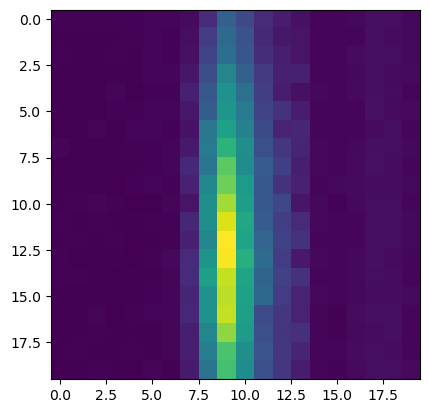

In [24]:
stamp, bg = get_stamp_from_df_eff(2967, snrs, posneg=None, norm=False, quad=None)

In [13]:
df = pd.read_csv(base_path+"df_snr_sobel_eff")

In [17]:
df.sort_values("sobel_ratio") #smallest at top
df_nodup = df.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant", "type"], keep="last")


Text(0.5, 1.0, 'Eff sobel ratios')

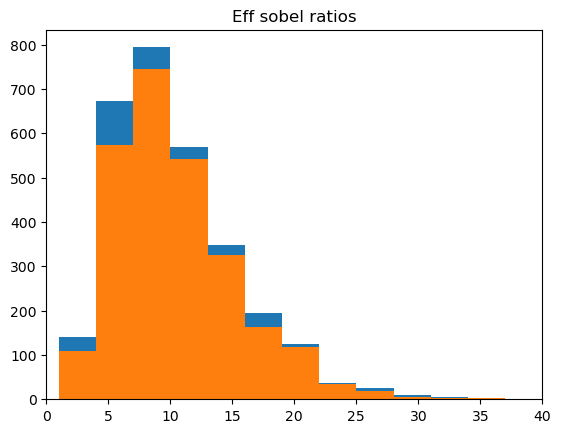

In [18]:
plt.hist(df['sobel_ratio'], bins=np.arange(1,np.max(df['sobel_ratio']),3))
plt.hist(df_nodup['sobel_ratio'],  label="nodup", bins=np.arange(1,np.max(df['sobel_ratio']),3))

plt.xlim(0,40)
plt.title("Eff sobel ratios")


In [33]:
np.max(df["Diff"])

4.978260869565247

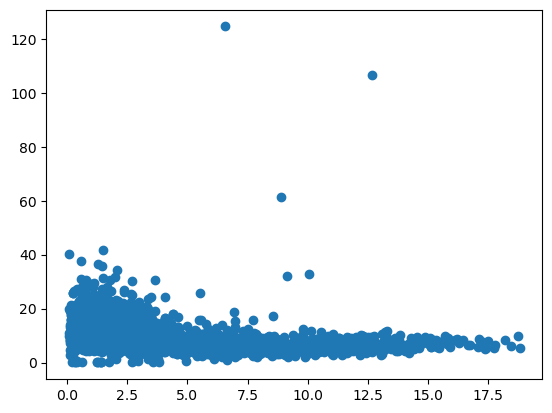

In [36]:
plt.scatter(df['snr_local'], df['sobel_ratio'])

In [15]:
df_highsob = df_nodup[df_nodup["sobel_ratio"]>5]

In [54]:
df_nodup[df_nodup["sobel_ratio"]<5]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,...,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,sobel_ratio,sobels_x,sobels_y
229,229,229,237,710,ztf_20221017148750_000831_zi_c04_x_0017.,52,neg,1508.173077,1203.326923,1214.0,...,3.128410,15.049494,15.018400,406.306620,22.802775,30.0,46.983711,4.930469,[[ 3.60020447e+00 -6.32034302e-01 2.89920349e...,[[-6.70210266e+00 -4.97227478e+00 -6.78848267e...
553,553,553,566,1720,ztf_20221014162894_000802_zg_c01_x_0009.,52,neg,2101.134615,3028.961538,3039.0,...,2.756248,15.040583,15.890961,527.929745,6.181454,38.0,43.799436,4.854211,[[ 3.86912994e+01 9.32783508e+00 -1.21618958e...,[[-6.12193298e+00 -1.82123566e+01 -1.28573914e...
616,616,616,636,1922,ztf_20221014162894_000802_zg_c01_x_0017.,64,neg,1935.984375,1322.359375,1332.0,...,2.250802,19.459158,25.159909,686.926583,5.569084,43.0,56.629975,4.965935,[[ 1.05559692e+01 -3.85809326e+00 -1.94523010e...,[[-2.38697510e+01 -1.81019287e+01 -6.39456177e...
621,621,621,641,1938,ztf_20221017148750_000831_zi_c03_x_0021.,64,neg,2129.125000,1097.921875,1108.0,...,2.342940,18.408559,18.837166,486.638786,7.029793,22.0,44.134354,4.677843,[[ 3.85032196e+01 1.78042603e+00 9.88113403e...,[[ 6.70426941e+00 2.97729492e-01 -5.51843262e...
740,740,740,764,2331,ztf_20221014162894_000802_zg_c01_x_0018.,69,neg,2962.942029,1123.275362,1133.0,...,4.683253,16.333657,17.781519,549.831078,1.006568,314.0,83.275351,4.743195,[[-1.15757751e+00 2.86512604e+01 1.49539337e...,[[-2.28043671e+01 -2.61501617e+01 -2.44929047e...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2898,2898,2898,2974,4844,ztf_20221020138241_000686_zi_c01_x_0004.,123,pos,2453.292683,2248.032520,2257.0,...,9.987273,25.291189,24.570701,820.762728,7234.917936,11.0,245.394291,4.306597,[[ 6.11596375e+01 1.76151779e+02 7.12539215e...,[[ 2.62600403e+01 4.41416931e+00 5.80961609e...
2903,2903,2903,2979,4849,ztf_20221020138241_000686_zi_c01_x_0004.,142,pos,1312.936620,1325.619718,1333.0,...,0.436580,920.148506,268.610657,1076.304230,1813.521453,10.0,117.270008,4.480950,[[ 3.24191498e+02 7.43512573e+01 -5.70461304e...,[[ 7.48951111e+01 6.65937500e+01 3.18842926e...
2908,2908,2908,2984,4861,ztf_20220820237546_000798_zr_c12_x_0004.,36,pos,2969.500000,1503.000000,1513.0,...,1.367070,11.124357,20.799922,239.961798,158.890802,8.0,28.434952,4.663915,[[-5.97137451e+00 -2.77020264e+01 -6.89790344e...,[[ 4.1535645 15.912964 19.246384 6.0...
2914,2914,2914,2990,4883,ztf_20221017148750_000831_zi_c03_x_0024.,121,pos,2258.438017,1926.132231,1937.0,...,3.103516,53.988114,49.191918,1345.117321,2822.615101,11.0,152.667906,3.818118,[[-2.96637421e+01 -4.00195618e+01 3.28129578e...,[[-1.41326752e+01 1.37918701e+01 2.51255035e...


(array([109.,  84.,   0.,  44.,   0.,  10.,   5.,   0.,   2.,   5.]),
 array([3. , 3.6, 4.2, 4.8, 5.4, 6. , 6.6, 7.2, 7.8, 8.4, 9. ]),
 <BarContainer object of 10 artists>)

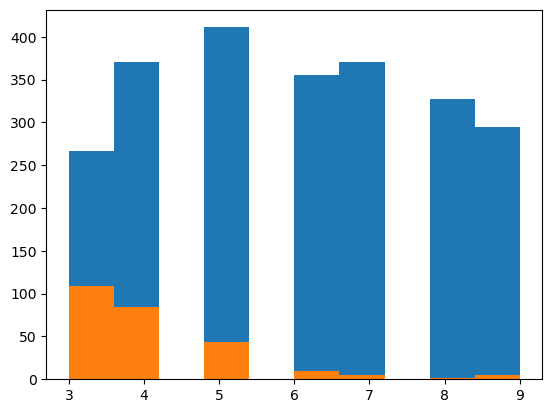

In [64]:
plt.hist(df_nodup[df_nodup["sobel_ratio"]>5]['sig_from_implant'])
plt.hist(df_nodup[df_nodup["sobel_ratio"]<5]['sig_from_implant'])

In [69]:
np.random.rand(1)-.5

array([-0.12653617])

In [17]:
df_nodup_pos = df_nodup[df_nodup['type']=='pos']

In [23]:
df_nodup_neg = df_nodup[df_nodup['type']=='neg']

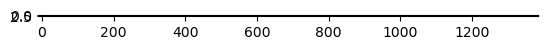

In [20]:
plt.imshow([df_nodup_pos['A_from_implant'],df_nodup_pos['sig_from_implant']+np.random.rand(len(df_nodup_pos))-.5, df_nodup_pos['sobel_ratio']])

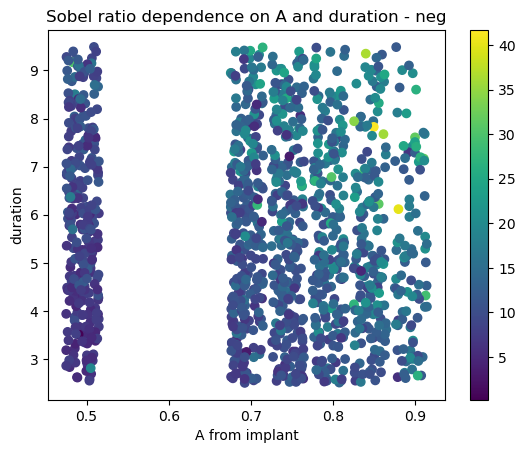

In [29]:
plt.scatter(df_nodup_neg['A_from_implant']+np.random.rand(len(df_nodup_neg))/25-.025,df_nodup_neg['sig_from_implant']+np.random.rand(len(df_nodup_neg))-.5, c=df_nodup_neg['sobel_ratio'])
plt.title('Sobel ratio dependence on A and duration - neg')
plt.xlabel("A from implant")
plt.ylabel("duration")
plt.colorbar()

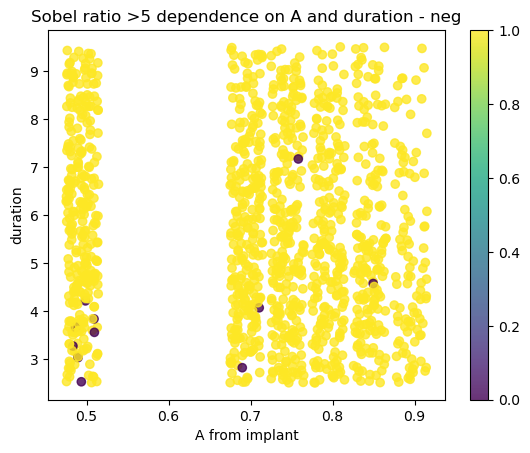

In [34]:
plt.scatter(df_nodup_neg['A_from_implant']+np.random.rand(len(df_nodup_neg))/25-.025,df_nodup_neg['sig_from_implant']+np.random.rand(len(df_nodup_neg))-.5, c=df_nodup_neg['sobel_ratio']>5, alpha=.8)
plt.title('Sobel ratio >5 dependence on A and duration - neg')
plt.xlabel("A from implant")
plt.ylabel("duration")
plt.colorbar()

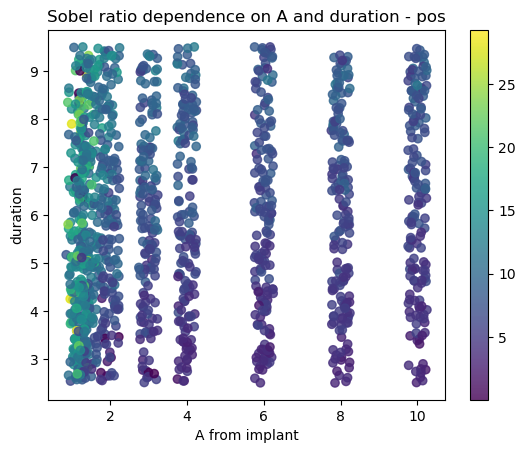

In [30]:
plt.scatter(df_nodup_pos['A_from_implant']+np.random.rand(len(df_nodup_pos))/2-.25,df_nodup_pos['sig_from_implant']+np.random.rand(len(df_nodup_pos))-.5, c=df_nodup_pos['sobel_ratio'], alpha=.8)
plt.title('Sobel ratio dependence on A and duration - pos')
plt.xlabel("A from implant")
plt.ylabel("duration")
plt.colorbar()

Text(0, 0.5, 'duration')

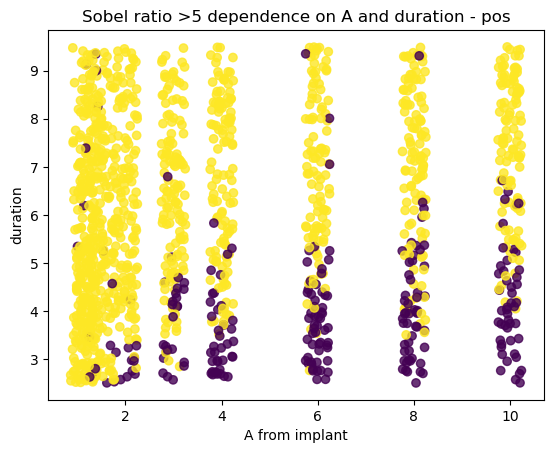

In [32]:
plt.scatter(df_nodup_pos['A_from_implant']+np.random.rand(len(df_nodup_pos))/2-.25,df_nodup_pos['sig_from_implant']+np.random.rand(len(df_nodup_pos))-.5, c=df_nodup_pos['sobel_ratio']>5, alpha=.8)
plt.title('Sobel ratio >5 dependence on A and duration - pos')
plt.xlabel("A from implant")
plt.ylabel("duration")
# plt.colorbar()

2430
269


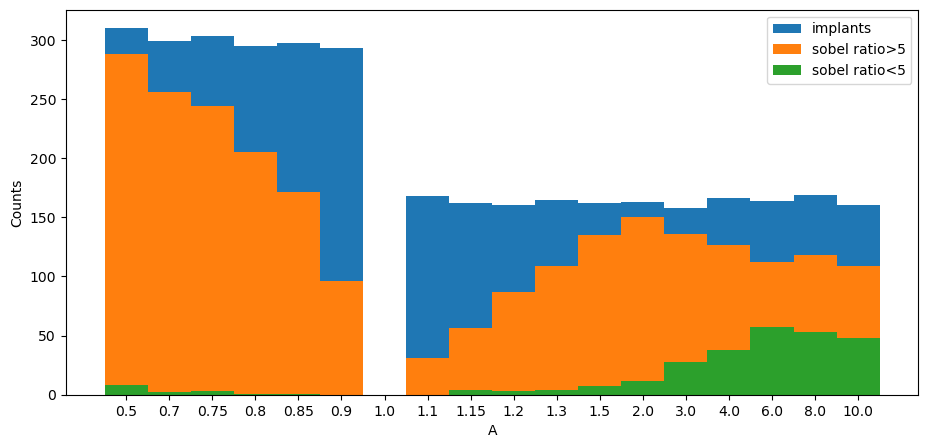

In [61]:
bins = binbounds
fig,ax = plt.subplots(figsize=(11,5))
alpha = 1

# implants = np.concatenate([df_implants_neg["A_from_implant"],df_implants_pos["A_from_implant"]])
hist_implants, bin_edges = np.histogram(implants,bins) # make the histogram
ax.bar(range(len(hist_implants)),hist_implants,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist_implants)], alpha=alpha, label="implants")


make_bar(df[df["sobel_ratio"]>5].sort_values("snr_local"), "sobel ratio>5", binbounds, ax, alpha=alpha)

make_bar(df[df["sobel_ratio"]<5].sort_values("snr_local"), "sobel ratio<5", binbounds, ax, alpha=alpha)
plt.ylabel("Counts")
plt.xlabel("A")
plt.legend()
plt.show()

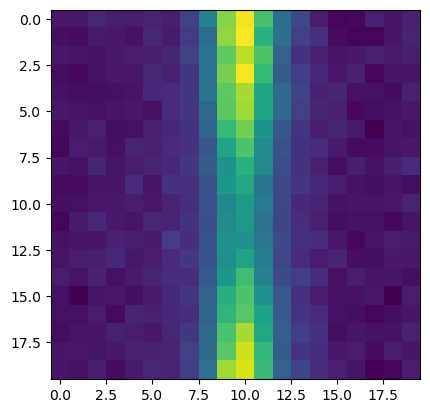

In [57]:
stamp, bg = get_stamp_from_df_eff(740, df_nodup, posneg=None, norm=False, quad=None)

2707
2693
2653
2430
2035


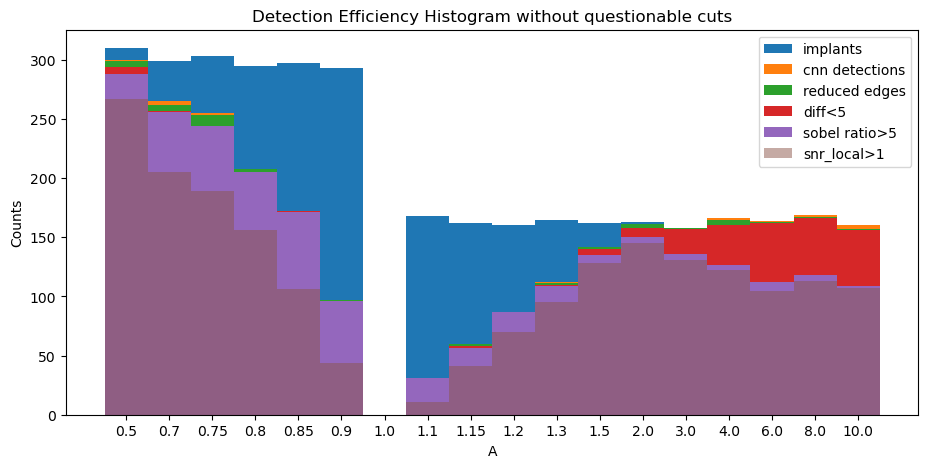

In [52]:
bins = binbounds
fig,ax = plt.subplots(figsize=(11,5))
alpha = 1

implants = np.concatenate([df_implants_neg["A_from_implant"],df_implants_pos["A_from_implant"]])
hist_implants, bin_edges = np.histogram(implants,bins) # make the histogram
ax.bar(range(len(hist_implants)),hist_implants,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist_implants)], alpha=alpha, label="implants")




make_bar(both, "cnn detections", binbounds, ax, alpha=alpha)
make_bar(noedges, "reduced edges", binbounds, ax, alpha=alpha)
# make_bar(matched[matched["Diff"]<10], "diff<10", binbounds, ax, alpha=alpha)
make_bar(matched[matched["Diff"]<5], "diff<5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>.5].sort_values("snr_local"), "snr>0.5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>1].sort_values("snr_local"), "snr>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>3].sort_values("snr_local"), "snr>3", binbounds, ax, alpha=alpha)
# snrdiff = snrs[snrs["Diff"]<5]
# make_bar(snrdiff[snrdiff["detection_size"]>1], "detection size>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>3], "detection size>3", binbounds, ax, alpha=alpha)
# make_bar(snrdiff[snrdiff["detection_size"]>5], "detection size>5", binbounds, ax, alpha=alpha)
make_bar(df[df["sobel_ratio"]>5].sort_values("snr_local"), "sobel ratio>5", binbounds, ax, alpha=alpha)
make_bar(df_highsob[df_highsob["snr_local"]>1].sort_values("snr_local"), "snr_local>1", binbounds, ax, alpha=.5)


plt.title("Detection Efficiency Histogram without questionable cuts")
plt.ylabel("Counts")
plt.xlabel("A")
plt.legend()
plt.show()



Text(0, 0.5, 'duration')

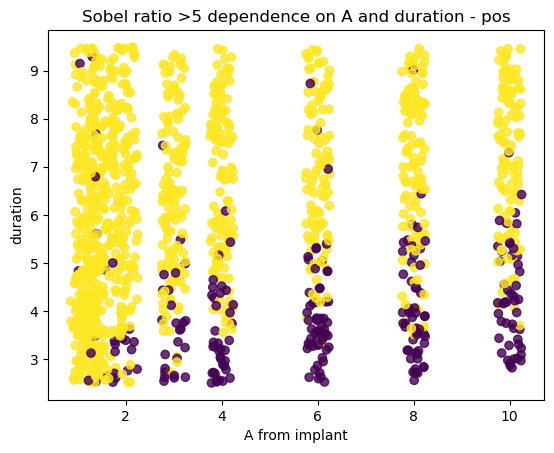

In [35]:
plt.scatter(df_nodup_pos['A_from_implant']+np.random.rand(len(df_nodup_pos))/2-.25,df_nodup_pos['sig_from_implant']+np.random.rand(len(df_nodup_pos))-.5, c=df_nodup_pos['sobel_ratio']>5, alpha=.8)
plt.title('Sobel ratio >5 dependence on A and duration - pos')
plt.xlabel("A from implant")
plt.ylabel("duration")
# plt.colorbar()

Text(0, 0.5, 'duration')

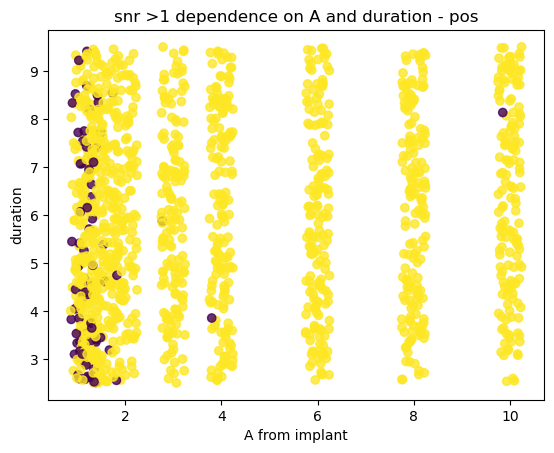

In [36]:
plt.scatter(df_nodup_pos['A_from_implant']+np.random.rand(len(df_nodup_pos))/2-.25,df_nodup_pos['sig_from_implant']+np.random.rand(len(df_nodup_pos))-.5, c=df_nodup_pos['snr_local']>1, alpha=.8)
plt.title('snr >1 dependence on A and duration - pos')
plt.xlabel("A from implant")
plt.ylabel("duration")
# plt.colorbar()

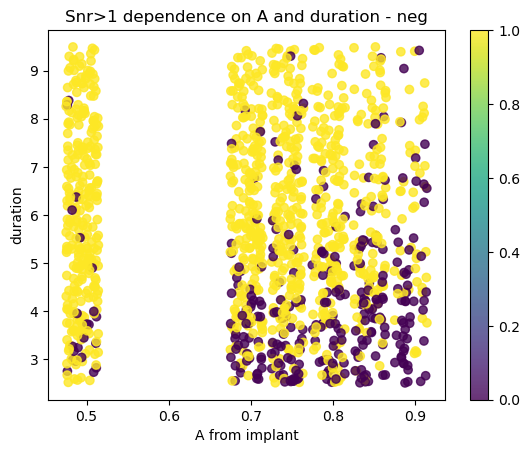

In [38]:
plt.scatter(df_nodup_neg['A_from_implant']+np.random.rand(len(df_nodup_neg))/25-.025,df_nodup_neg['sig_from_implant']+np.random.rand(len(df_nodup_neg))-.5, c=df_nodup_neg['snr_local']>1, alpha=.8)
plt.title('Snr>1 dependence on A and duration - neg')
plt.xlabel("A from implant")
plt.ylabel("duration")
plt.colorbar()

In [19]:
df

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,...,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,sobel_ratio,sobels_x,sobels_y
0,0,0,0,15,ztf_20221020138241_000686_zi_c03_x_0015.,45,neg,2489.466667,1110.488889,1119.0,...,1.700951,35.282512,32.266191,1257.002297,8.147728,36.0,54.883216,9.265618,[[-1.4316696e+01 -3.4800369e+01 4.7301239e+01...,[[ 3.23011017e+01 2.60682526e+01 2.23672180e...
1,1,1,1,16,ztf_20221020138241_000686_zi_c03_x_0015.,59,neg,2287.033898,428.288136,439.0,...,2.254720,43.828481,42.149178,1793.318469,217.928699,28.0,95.034585,8.493932,[[-5.36508179e+01 -2.58056946e+01 -7.58950806e...,[[ 4.13299561e+00 1.46388245e+01 2.72944641e...
2,2,2,2,17,ztf_20221020138241_000686_zi_c03_x_0015.,6,neg,1969.333333,1909.166667,1919.0,...,0.408782,34.521041,36.943204,1512.000365,12.041017,11.0,15.101714,21.079361,[[-7.87734985e-01 -1.65223236e+01 8.56109619e...,[[-1.50125885e+01 7.92362976e+00 1.33149109e...
3,3,3,3,18,ztf_20221020138241_000686_zi_c03_x_0015.,42,neg,1806.547619,2355.071429,2367.0,...,1.101981,75.021943,189.311490,2684.395555,426.086134,83.0,208.617627,14.120044,[[ 3.65085602e+01 8.79525757e+00 -2.15327454e...,[[ 1.51270905e+01 1.44348145e+00 -1.67867432e...
4,4,4,4,19,ztf_20221020138241_000686_zi_c03_x_0015.,63,neg,1364.238095,958.158730,969.0,...,2.066340,58.369706,62.687993,2775.906774,299.739049,34.0,129.534688,20.508022,[[-6.36863708e+00 -1.64357758e+01 -2.99932709e...,[[ 1.08346710e+01 2.40997162e+01 1.80276031e...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2937,2937,2937,3013,4961,ztf_20221014162894_000802_zg_c01_x_0005.,186,pos,1981.935484,1598.317204,1608.0,...,9.893450,23.907304,19.263678,531.883134,2842.950851,17.0,190.584228,7.726455,[[ 6.63540649e+00 1.16503906e+00 -4.13386536e...,[[-1.52251892e+01 -1.07204590e+01 -7.94142151e...
2938,2938,2938,3014,4962,ztf_20221014162894_000802_zg_c01_x_0005.,213,pos,1326.230047,1322.638498,1332.0,...,10.843435,22.340100,21.347214,680.578675,3508.962340,20.0,231.477115,6.605589,[[ 1.75475769e+01 -5.16107178e+00 1.71146851e...,[[ 1.04263000e+01 3.46624756e+00 8.90850830e...
2939,2939,2939,3015,4963,ztf_20221014162894_000802_zg_c01_x_0005.,183,pos,1319.743169,1809.453552,1819.0,...,6.709530,19.055547,23.869923,828.773415,1686.094749,20.0,160.155956,9.666578,[[ 7.89305115e+00 -3.73003387e+01 8.94810486e...,[[ 3.11981659e+01 2.94294891e+01 2.00558929e...
2940,2940,2940,3016,4964,ztf_20221014162894_000802_zg_c01_x_0005.,56,pos,855.785714,2303.142857,2313.0,...,2.546913,18.054324,21.351623,711.195442,384.965446,11.0,54.380721,10.097983,[[-1.71416931e+02 -2.20630768e+02 -6.83542023e...,[[ 1.69671631e+01 1.24594116e+00 -1.30390167e...


In [27]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [29]:
df_normsob = rff.add_normsobel_stuff(df, eff=True)

/home/3155/rwe/review_findings_functions.py:2431: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_norm_stdv_rat'].loc[i] = np.std(xnorm)/np.std(ynorm)
/home/3155/rwe/review_findings_functions.py:2432: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_norm_diffmax'].loc[i] = np.max(xnorm)/np.max(ynorm)


Text(0.5, 1.0, 'Sobel stdv ratio - efficiency data')

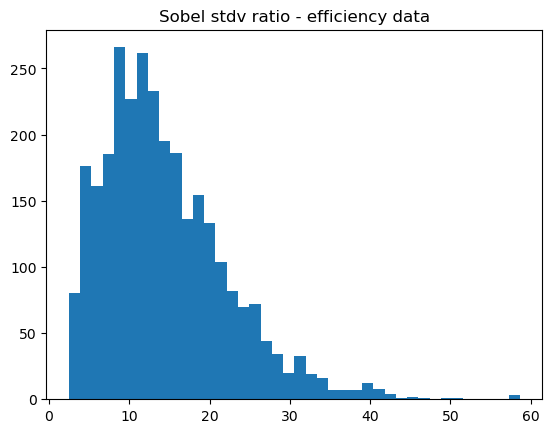

In [48]:
plt.hist(df_normsob['sobel_norm_stdv_rat'], bins=40)
plt.title("Sobel stdv ratio - efficiency data")
# plt.xlim(-1,10)

In [41]:
sorte = df_normsob.sort_values('sobel_norm_stdv_rat')

In [43]:
drop = sorte.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])

In [44]:
np.min(drop['sobel_norm_stdv_rat'])

2.4701130390167236

In [35]:
np.min(df_normsob['sobel_norm_stdv_rat'])

2.4701130390167236

(array([ 65., 572., 829., 661., 372., 217., 140.,  37.,  25.,  11.,   4.,
          3.,   2.,   1.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   1.,   0.,   0.,   0.,   0.,   1.]),
 array([1.96610596e-02, 3.13364459e+00, 6.24762813e+00, 9.36161166e+00,
        1.24755952e+01, 1.55895787e+01, 1.87035623e+01, 2.18175458e+01,
        2.49315293e+01, 2.80455129e+01, 3.11594964e+01, 3.42734799e+01,
        3.73874635e+01, 4.05014470e+01, 4.36154305e+01, 4.67294141e+01,
        4.98433976e+01, 5.29573811e+01, 5.60713647e+01, 5.91853482e+01,
        6.22993317e+01, 6.54133153e+01, 6.85272988e+01, 7.16412823e+01,
        7.47552659e+01, 7.78692494e+01, 8.09832329e+01, 8.40972165e+01,
        8.72112000e+01, 9.03251835e+01, 9.34391671e+01, 9.65531506e+01,
        9.96671341e+01, 1.02781118e+02, 1.05895101e+02, 1.09009085e+02,
        1.12123068e+02, 1.15237052e+02, 1.18351035e+02, 1.21465019e+02,
      

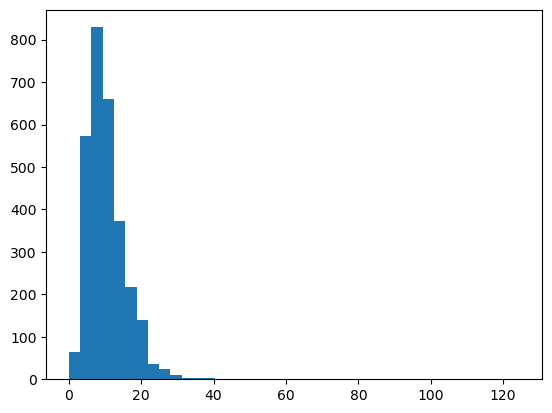

In [38]:

plt.hist(df_normsob['sobel_norm_diffmax'], bins=40)

Text(0, 0.5, 'duration')

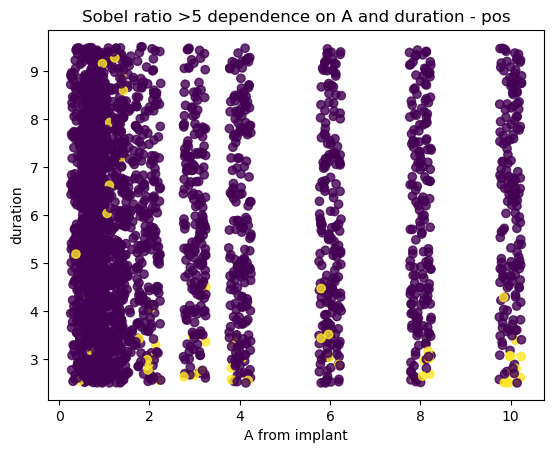

In [49]:
plt.scatter(df_normsob['A_from_implant']+np.random.rand(len(df_normsob))/2-.25,df_normsob['sig_from_implant']+np.random.rand(len(df_normsob))-.5, c=df_normsob['sobel_norm_diffmax']<3, alpha=.8)
plt.title('Sobel ratio >5 dependence on A and duration - pos')
plt.xlabel("A from implant")
plt.ylabel("duration")

In [16]:
df_eff_normsob = pd.read_csv(base_path+"df_eff_normsob")

2707
2693
2653
2645
2507


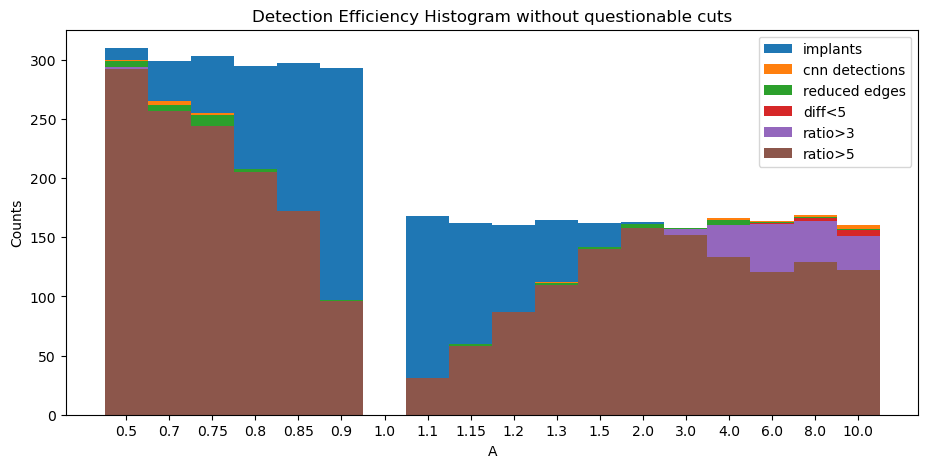

In [27]:
bins = binbounds
fig,ax = plt.subplots(figsize=(11,5))
alpha = 1

implants = np.concatenate([df_implants_neg["A_from_implant"],df_implants_pos["A_from_implant"]])
hist_implants, bin_edges = np.histogram(implants,bins) # make the histogram
ax.bar(range(len(hist_implants)),hist_implants,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist_implants)], alpha=alpha, label="implants")




make_bar(both, "cnn detections", binbounds, ax, alpha=alpha)
make_bar(noedges, "reduced edges", binbounds, ax, alpha=alpha)
# make_bar(matched[matched["Diff"]<10], "diff<10", binbounds, ax, alpha=alpha)
make_bar(matched[matched["Diff"]<5], "diff<5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>.5].sort_values("snr_local"), "snr>0.5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>1].sort_values("snr_local"), "snr>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>3].sort_values("snr_local"), "snr>3", binbounds, ax, alpha=alpha)
# snrdiff = snrs[snrs["Diff"]<5]
# make_bar(snrdiff[snrdiff["detection_size"]>1], "detection size>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>3], "detection size>3", binbounds, ax, alpha=alpha)
# make_bar(snrdiff[snrdiff["detection_size"]>5], "detection size>5", binbounds, ax, alpha=alpha)
# make_bar(df_eff_normsob[df_eff_normsob["snr_local"]>1].sort_values("snr_local"), "snr_local>1", binbounds, ax, alpha=alpha)
# make_bar(df_eff_normsob[df_eff_normsob["sobel_ratio"]>5].sort_values("snr_local"), "sobel ratio>5", binbounds, ax, alpha=.5)
make_bar(df_eff_normsob[df_eff_normsob["sobel_norm_stdv_rat"]>3].sort_values("snr_local"), "ratio>3", binbounds, ax, alpha=alpha)
make_bar(df_eff_normsob[df_eff_normsob["sobel_norm_stdv_rat"]>5].sort_values("snr_local"), "ratio>5", binbounds, ax, alpha=alpha)
# make_bar(df_eff_normsob[df_eff_normsob["sobel_ratio"]>5].sort_values("snr_local"), "sobel ratio>5", binbounds, ax, alpha=.5)


plt.title("Detection Efficiency Histogram without questionable cuts")
plt.ylabel("Counts")
plt.xlabel("A")
plt.legend()
plt.show()



In [28]:
snrs

,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,...,brightness_ranking,quadrant,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
0,0,15,ztf_20221020138241_000686_zi_c03_x_0015.,45,neg,2489.466667,1110.488889,1119.0,2500.0,0.80,...,7.0,1,1.555536,1.700951,35.282512,32.266191,1257.002297,8.147728,36.0,54.883216
1,1,16,ztf_20221020138241_000686_zi_c03_x_0015.,59,neg,2287.033898,428.288136,439.0,2297.0,0.70,...,4.0,1,2.168329,2.254720,43.828481,42.149178,1793.318469,217.928699,28.0,95.034585
2,2,17,ztf_20221020138241_000686_zi_c03_x_0015.,6,neg,1969.333333,1909.166667,1919.0,1980.0,0.90,...,3.0,1,0.437464,0.408782,34.521041,36.943204,1512.000365,12.041017,11.0,15.101714
3,3,18,ztf_20221020138241_000686_zi_c03_x_0015.,42,neg,1806.547619,2355.071429,2367.0,1818.0,0.85,...,2.0,1,2.780755,1.101981,75.021943,189.311490,2684.395555,426.086134,83.0,208.617627
4,4,19,ztf_20221020138241_000686_zi_c03_x_0015.,63,neg,1364.238095,958.158730,969.0,1375.0,0.70,...,0.0,1,2.219211,2.066340,58.369706,62.687993,2775.906774,299.739049,34.0,129.534688
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2937,3013,4961,ztf_20221014162894_000802_zg_c01_x_0005.,186,pos,1981.935484,1598.317204,1608.0,1994.0,6.00,...,6.0,1,7.971799,9.893450,23.907304,19.263678,531.883134,2842.950851,17.0,190.584228
2938,3014,4962,ztf_20221014162894_000802_zg_c01_x_0005.,213,pos,1326.230047,1322.638498,1332.0,1339.0,6.00,...,5.0,1,10.361508,10.843435,22.340100,21.347214,680.578675,3508.962340,20.0,231.477115
2939,3015,4963,ztf_20221014162894_000802_zg_c01_x_0005.,183,pos,1319.743169,1809.453552,1819.0,1332.0,3.00,...,3.0,1,8.404689,6.709530,19.055547,23.869923,828.773415,1686.094749,20.0,160.155956
2940,3016,4964,ztf_20221014162894_000802_zg_c01_x_0005.,56,pos,855.785714,2303.142857,2313.0,866.0,1.50,...,4.0,1,3.012061,2.546913,18.054324,21.351623,711.195442,384.965446,11.0,54.380721


In [29]:
pd.read_csv(base_path+"df_snr_sobel_eff")

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,...,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,sobel_ratio,sobels_x,sobels_y
0,0,0,0,15,ztf_20221020138241_000686_zi_c03_x_0015.,45,neg,2489.466667,1110.488889,1119.0,...,1.700951,35.282512,32.266191,1257.002297,8.147728,36.0,54.883216,9.265618,[[-1.4316696e+01 -3.4800369e+01 4.7301239e+01...,[[ 3.23011017e+01 2.60682526e+01 2.23672180e...
1,1,1,1,16,ztf_20221020138241_000686_zi_c03_x_0015.,59,neg,2287.033898,428.288136,439.0,...,2.254720,43.828481,42.149178,1793.318469,217.928699,28.0,95.034585,8.493932,[[-5.36508179e+01 -2.58056946e+01 -7.58950806e...,[[ 4.13299561e+00 1.46388245e+01 2.72944641e...
2,2,2,2,17,ztf_20221020138241_000686_zi_c03_x_0015.,6,neg,1969.333333,1909.166667,1919.0,...,0.408782,34.521041,36.943204,1512.000365,12.041017,11.0,15.101714,21.079361,[[-7.87734985e-01 -1.65223236e+01 8.56109619e...,[[-1.50125885e+01 7.92362976e+00 1.33149109e...
3,3,3,3,18,ztf_20221020138241_000686_zi_c03_x_0015.,42,neg,1806.547619,2355.071429,2367.0,...,1.101981,75.021943,189.311490,2684.395555,426.086134,83.0,208.617627,14.120044,[[ 3.65085602e+01 8.79525757e+00 -2.15327454e...,[[ 1.51270905e+01 1.44348145e+00 -1.67867432e...
4,4,4,4,19,ztf_20221020138241_000686_zi_c03_x_0015.,63,neg,1364.238095,958.158730,969.0,...,2.066340,58.369706,62.687993,2775.906774,299.739049,34.0,129.534688,20.508022,[[-6.36863708e+00 -1.64357758e+01 -2.99932709e...,[[ 1.08346710e+01 2.40997162e+01 1.80276031e...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2937,2937,2937,3013,4961,ztf_20221014162894_000802_zg_c01_x_0005.,186,pos,1981.935484,1598.317204,1608.0,...,9.893450,23.907304,19.263678,531.883134,2842.950851,17.0,190.584228,7.726455,[[ 6.63540649e+00 1.16503906e+00 -4.13386536e...,[[-1.52251892e+01 -1.07204590e+01 -7.94142151e...
2938,2938,2938,3014,4962,ztf_20221014162894_000802_zg_c01_x_0005.,213,pos,1326.230047,1322.638498,1332.0,...,10.843435,22.340100,21.347214,680.578675,3508.962340,20.0,231.477115,6.605589,[[ 1.75475769e+01 -5.16107178e+00 1.71146851e...,[[ 1.04263000e+01 3.46624756e+00 8.90850830e...
2939,2939,2939,3015,4963,ztf_20221014162894_000802_zg_c01_x_0005.,183,pos,1319.743169,1809.453552,1819.0,...,6.709530,19.055547,23.869923,828.773415,1686.094749,20.0,160.155956,9.666578,[[ 7.89305115e+00 -3.73003387e+01 8.94810486e...,[[ 3.11981659e+01 2.94294891e+01 2.00558929e...
2940,2940,2940,3016,4964,ztf_20221014162894_000802_zg_c01_x_0005.,56,pos,855.785714,2303.142857,2313.0,...,2.546913,18.054324,21.351623,711.195442,384.965446,11.0,54.380721,10.097983,[[-1.71416931e+02 -2.20630768e+02 -6.83542023e...,[[ 1.69671631e+01 1.24594116e+00 -1.30390167e...


In [33]:
matched[matched["Diff"]>5]

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,closest_x,closest_y,Diff,brightness_ranking,quadrant
46,165,ztf_20221020138241_000686_zi_c01_x_0017.,2,neg,2703.500000,1314.000000,1332.0,2723.0,0.90,7.0,1332.0,2797.0,8.000000,4.0,1
52,171,ztf_20221020138241_000686_zi_c01_x_0017.,21,neg,1009.904762,1314.476190,1325.0,1020.0,0.70,7.0,1332.0,2797.0,7.523810,4.0,1
55,174,ztf_20221020138241_000686_zi_c01_x_0017.,46,neg,249.130435,327.456522,337.0,259.0,0.70,6.0,454.0,2067.0,116.543478,2.0,1
94,287,ztf_20221020138241_000686_zi_c01_x_0027.,29,neg,646.758621,327.103448,337.0,657.0,0.75,5.0,454.0,2067.0,116.896552,2.0,1
125,380,ztf_20221020138241_000686_zi_c01_x_0009.,27,neg,972.185185,328.333333,338.0,982.0,0.80,5.0,454.0,2067.0,115.666667,2.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2522,3436,ztf_20220820237546_000798_zr_c12_x_0001.,80,pos,2876.012500,204.287500,214.0,2889.0,3.00,9.0,340.0,285.0,125.712500,17.0,1
2672,3897,ztf_20220820237546_000798_zr_c16_x_0001.,124,pos,1722.661290,594.846774,605.0,1734.0,8.00,6.0,611.0,320.0,6.153226,3.0,1
2725,4048,ztf_20221020138241_000686_zi_c01_x_0027.,239,pos,642.882845,329.276151,337.0,657.0,10.00,7.0,454.0,2067.0,114.723849,2.0,1
2767,4180,ztf_20221020138241_000686_zi_c01_x_0017.,45,pos,244.266667,328.533333,337.0,259.0,1.50,8.0,454.0,2067.0,115.466667,2.0,1


8.0


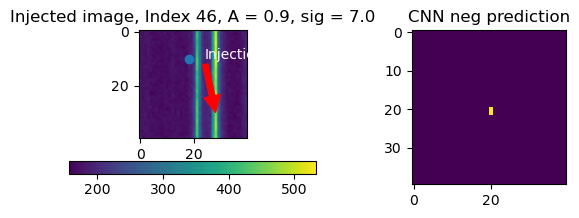

7.523809523809632


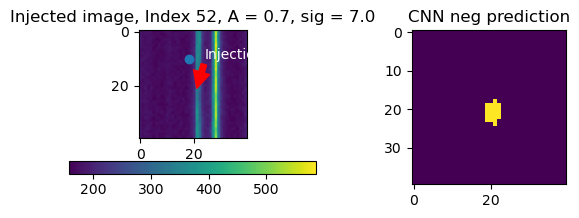

116.54347826086956


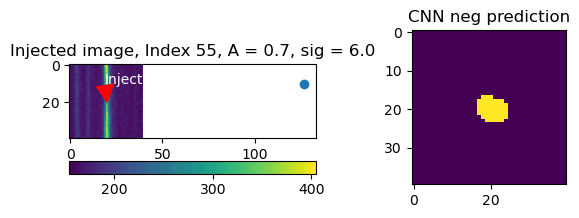

-11.0


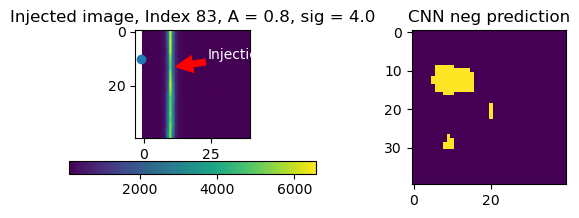

116.89655172413791


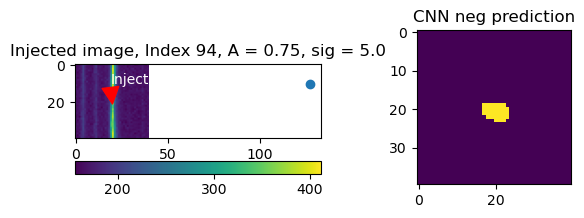

115.66666666666669


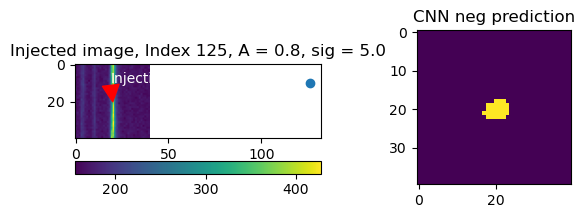

6.022222222221899


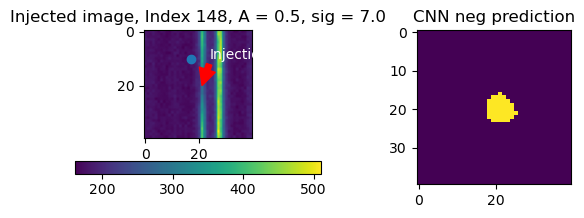

6.0


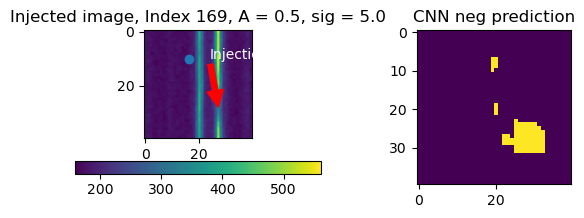

5.9729729729729115


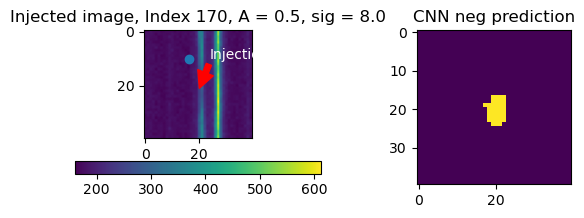

-5.375


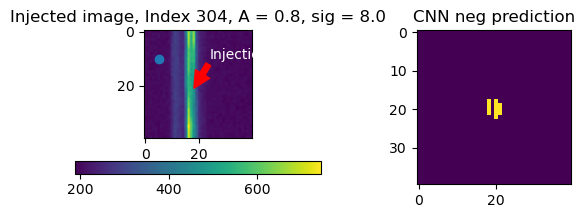

115.89999999999998


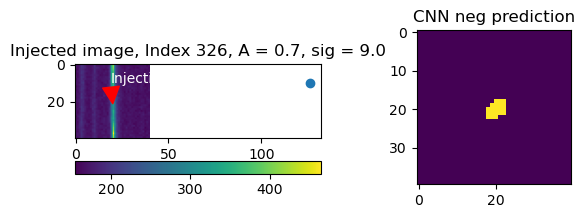

-74.05000000000018


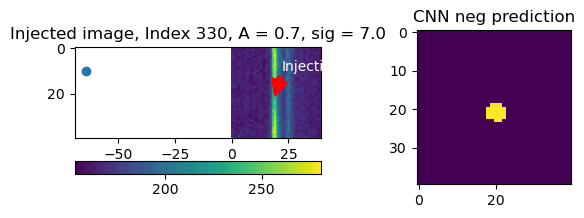

7.0


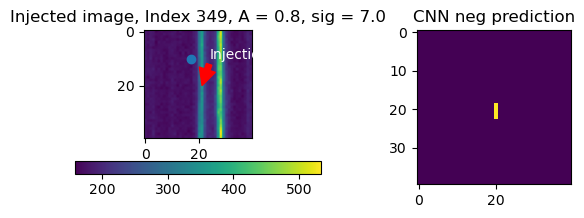

6.5


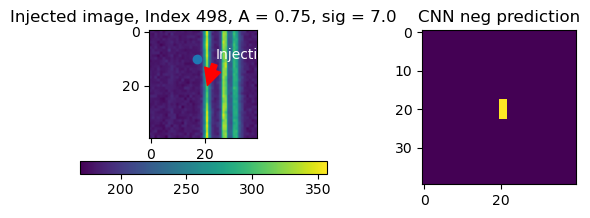

-201.33333333333337


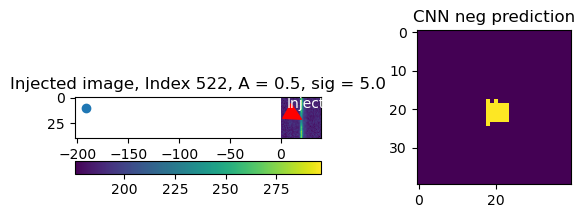

6.769230769230717


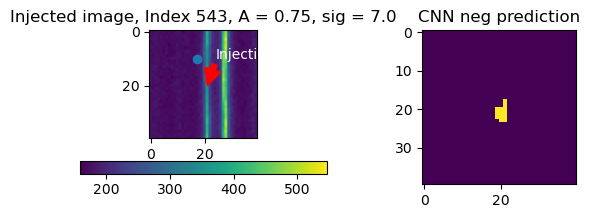

7.0


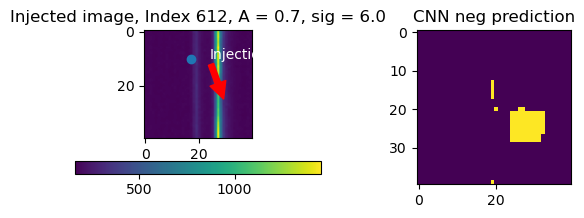

8.0


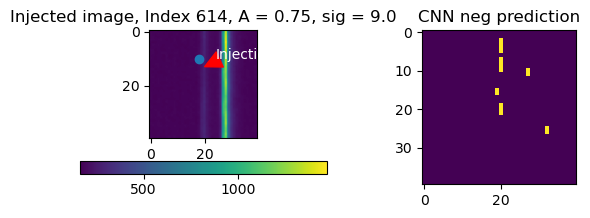

9.0


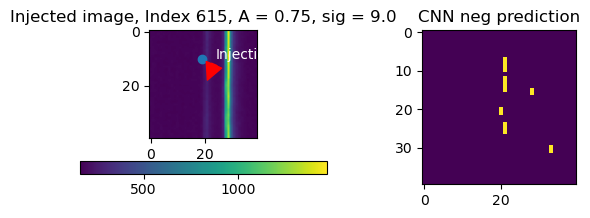

8.0


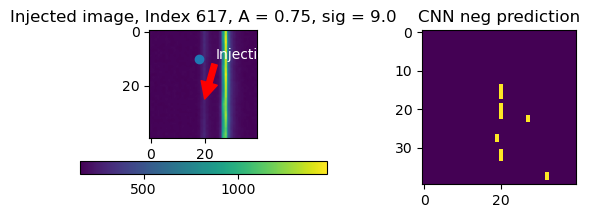

In [42]:
for index in matched[np.abs(matched["Diff"])>5].index[:20]:
    print(matched.loc[index, "Diff"])
    inspect_stamp_and_map(matched, index, matched.loc[index]["type"], size=20, column=None, nn_or_imp="nn", thr=True, star=True)
    # tot, maxcols = rff.get_tot_npy(matched, index, posneg = matched.loc[index]["type"])
    # plt.scatter(range(len(tot)),tot)
    # plt.xlim(matched.loc[index]["row_from_nn"]+10-130,matched.loc[index]["row_from_nn"]+10+130)
    # plt.show()